# 3-servo: sag

Run the servo at thirteen rails from a full 2S pack at 8.4 V down to its floor at 6.0 V, and read the board's rail, the current zero, the resistance in a stop lap, a slow crawl and a 30 % spin at each, then hold a stall while the rail steps down, so the rail-tracking duty cap, the zero tracker and the undervolt design of stage 6 have numbers for every state of charge.

## Purpose

A servo on a 2S lithium pack sees its rail fall from 8.4 V when the pack is full to about 6.0 V near its floor. Three parts of the firmware depend on that rail.

- The rail-tracking duty cap limits the duty so the rail times the duty never exceeds the motor's rated 5 V. Its value is $100 \times 5 / V_\mathrm{rail}$ percent, so it needs the rail as the board reads it, and its step per 0.2 V of rail says how finely the firmware has to track the rail.
- The zero tracker is the firmware's running estimate of the current channel's zero, the reading with no current in the motor. If the zero moves with the rail, the tracker needs a rail term.
- The undervolt behavior stage 6 designs needs to know what the servo does at a given effective drive as the rail falls, both turning slowly and held in a stall.

The motor sees an effective voltage, $V_\mathrm{eff}$ ("V effective"), the terminal voltage while the bridge is on times the duty. A servo that holds $V_\mathrm{eff}$ fixed while the rail falls should behave the same at every rail. Whether it does, and what the board's own readings do as the rail moves, is the question here.

The type values come from stage 2, measured on the bare motors mg90-b and mg90-c, and are used for comparison only. mg90-d's motor was never opened, so every number for it here is read through the assembled servo.

## Procedure

The servo is mg90-d on board dev-v006-2A-D, horn free, powered from the DPS-150 bench supply over the board's feed diode. The board runs the experiment image, so every drive is open loop with only the raw current trip and the bus dead-man as protections. The sitting runner, `python -m oscnb.sitting servo --include sag/capture`, ran `stages/3-servo/sag/plan.py`.

capture-1 steps the DPS down 0.2 V at a time, from 8.4 V to 6.0 V, thirteen rails. At each rail it trims the DPS until the board's rail reads the level, then runs three sweeps with torque off between them.

1. `stop`, a 300 ms lap of 1.5 V effective into the low end stop, direction -1. The duty is rounded to a whole percent of the rail, 18 % at 8.4 V to 25 % at 6.0 V.
2. `crawl`, both directions. A 150 ms kick at 1.5 V effective, then a hold at 0.5 V effective that the runway allows, about 1.2 s, then a 400 ms coast with the bridge open.
3. `cycle`, both directions. A spin at 30 % duty for as long as the runway allows, 202 ms at 8.4 V to 335 ms at 6.0 V, then a 400 ms coast.

The DPS steps only between sweeps with torque off. A DPS step down has reset the servo once before, so no drive in capture-1 spans a step.

held-5, run in a later sitting with `--include sag/held`, holds a stall at 12 % duty, 1.0 V effective on the 8.4 V rail, into the horn lock, the rigid stop a pin through the horn makes, while the DPS steps down the same rails. Only a 100 ms window before the first step and one after the hold are streamed, and the hold between them is not.

## Data

Everything is under `telemetry/mg90-d__dev-v006-2A-D/`. capture-1 and held-5 are in `sag/`, and the two sittings' manifests are in `sittings/servo-1.csv` and `sittings/servo-5.csv`.

The libraries, then the pair and its folders.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from oscnb import boards, coast, figures, motors, results, ripple, scales
from oscnb import manifest, servos, tel
from oscnb.results import fit_line
from oscnb.display import show
from oscnb.figures import BLUE, GREEN, INK, MUTED, ORANGE

In [2]:
SERVO = servos.SERVOS["mg90-d"]         # the servo: pot, train, rated V
MOTOR = motors.MOTORS[SERVO.motor]      # its motor, with its counted parts
BOARD_KEY = boards.DEFAULT              # the board, checked on every sweep
PAIR = f"{SERVO.key}__{BOARD_KEY}"      # the pair, the result file's name
PAIR_DIR = (Path("../../../telemetry") / PAIR).resolve()
CAPTURE = PAIR_DIR / "sag" / "capture-1"    # the first pass, 13 rails
HELD = PAIR_DIR / "sag" / "held-5"          # the stall held through steps
MANIFEST_1 = PAIR_DIR / "sittings" / "servo-1.csv"   # capture-1's sitting
MANIFEST_5 = PAIR_DIR / "sittings" / "servo-5.csv"   # held-5's sitting
FS = 20_000                             # rows per second, the control tick
print(SERVO.key, "on", BOARD_KEY, "from", results.rel(CAPTURE), "and",
      results.rel(HELD))
print(f"{MOTOR.label}: {MOTOR.slots} slots, {MOTOR.brushes} brushes, "
      f"rows at {FS} Hz")

mg90-d on dev-v006-2A-D from telemetry/mg90-d__dev-v006-2A-D/sag/capture-1 and telemetry/mg90-d__dev-v006-2A-D/sag/held-5
the motor of MG90 clone d: 3 slots, 2 brushes, rows at 20000 Hz


Every sweep names its board in its own `meta.json`. The board is looked up from that sense block, never assumed, and its check raises if any constant disagrees with the registry.

In [3]:
def board_of(meta, where=""):
    """The board a sweep's meta names, its sense block checked."""
    board = boards.from_meta(meta)      # identified from the data itself
    if board is None:
        raise ValueError(f"{where}: no board matches {meta['sense']}")
    board.check_meta(meta, where)       # raises on any mismatch
    return board


def load(folder):
    """(frame, meta, board) of one sweep, through the chain."""
    frame, meta = tel.load(folder)
    return frame, meta, board_of(meta, str(results.rel(folder)))

### Stage 1 values carried in

The current goes through the current-scale result and the terminal and rail volts through the terminal-chain result, both graded on this board in stage 1. Bridge-states gives the low-side loop's resistance, used for one comparison.

In [4]:
SCALES = scales.load(BOARD_KEY)         # stage 1's current and volt lines
# multiplied as the stage 2 files were computed, never divided: a ripple
# count downstream turns a last-bit change into a moved result
A_PER_COUNT = SCALES.a_per_count        # amps per count over the zero
V_PER_COUNT = SCALES.v_per_count        # volts per count of tap difference
TAP_OFFSET = SCALES.terminal_offset_counts   # the tap difference's offset
BRIDGE = results.read("1-board", "bridge-states", pair=BOARD_KEY)
LOW_SIDE_OHM = BRIDGE["low_side_loop_ohm"]["value"]   # the low-side loop
SCALES.describe()
print(f"a count over the zero is {A_PER_COUNT * 1e3:.3f} mA, a count of tap "
      f"difference {V_PER_COUNT * 1e3:.3f} mV")
print(f"low-side loop {LOW_SIDE_OHM:.2f} ohm, from bridge-states")

current: counts over the zero = +5.3 + 1135.0 x amps (1133.8 to 1136.3), graded over 0.23 to 1.31 A
terminals: tap difference = +2.4 + 248.37 x volts (248.20 to 248.53)
rail: tap = +6.0 + 247.54 x volts at rest
bridge ON edge 40 ticks after the commanded start, shunt crossing 44, OFF edge 14 after the commanded end, shunt settled 72 after the start
fast decay: ON edge 8 ticks after the commanded start, OFF edge 12 after the end
a count over the zero is 0.881 mA, a count of tap difference 4.026 mV
low-side loop 0.30 ohm, from bridge-states


### Stage 2 type values carried in

mg90-b is the type motor of this family and mg90-c the second motor. Their stage 2 results give the resistance, the back-EMF constant and the reading term this notebook compares against, never a constant it computes with for mg90-d's own results.

In [5]:
TYPE_KEY = SERVO.type_motor             # mg90-b
RR_TYPE = results.read("2-motor", "rest-resistance", pair=TYPE_KEY)
BC_TYPE = results.read("2-motor", "bemf-coast", pair=TYPE_KEY)
RR_SPREAD = results.read("2-motor", "rest-resistance", pair="mg90-c")
BC_SPREAD = results.read("2-motor", "bemf-coast", pair="mg90-c")
R_TYPE = RR_TYPE["r_term_median_ohm"]["value"]     # ohm, locked, 100 %
KE_TYPE_MV = BC_TYPE["ke_mv_per_rev_s"]["value"]   # mV per rev/s
KE = KE_TYPE_MV * 1e-3                  # V per rev/s, the type's Ke
G_READ = BC_TYPE["reading_term_a_per_v"]["value"]  # A per V of window
WARM_TYPE = RR_TYPE["warming_pct_per_j"]["value"]  # % per J, locked laps
V0_TYPE = RR_TYPE["v0_brush_v"]["value"]           # V, the brush drop
print(f"{TYPE_KEY}: R {R_TYPE:.3f} ohm, Ke {KE_TYPE_MV:.4f} mV per rev/s, "
      f"reading term {G_READ * 1e3:.2f} mA/V, warming {WARM_TYPE:.2f} %/J, "
      f"V0 {V0_TYPE:.2f} V")
print(f"mg90-c: R {RR_SPREAD['r_term_median_ohm']['value']:.3f} ohm, Ke "
      f"{BC_SPREAD['ke_mv_per_rev_s']['value']:.4f} mV per rev/s")

mg90-b: R 4.455 ohm, Ke 7.3411 mV per rev/s, reading term 4.29 mA/V, warming 2.86 %/J, V0 0.06 V
mg90-c: R 4.402 ohm, Ke 7.3162 mV per rev/s


The servo's counted parts, and the constants of the method, each with its unit and reason.

In [6]:
N_R = MOTOR.slots * MOTOR.brushes       # ripple events per motor rev
GEAR = SERVO.gear_ratio                 # counted teeth, motor revs per out
# the pot's nominal slope, a sizing number pot-table grades, so speeds
# through it are labelled nominal; never used to derive the gear ratio
COUNTS_PER_OUT_REV = SERVO.counts_per_deg_nominal * 360.0
RATED_V = SERVO.rated_v                 # V, the motor's rated volts
SKIP = 40                               # rows, 2 ms into a rung, settled
EARLY = slice(SKIP, SKIP + 1000)        # a lap's first 50 ms after SKIP
LATE = slice(-1000, None)               # a lap's last 50 ms
COPPER_PCT_PER_C = 0.39                 # % per C, copper's coefficient
TAIL_ZERO_ROWS = 2000                   # rows, a coast's last 100 ms
TAIL_ROWS = 8000                        # rows, the crawl hold's last 400 ms
BIN_ROWS = 1000                         # rows, 50 ms bins down the hold
MOVE_COUNTS = 3                         # counts, pos has left its seat
LOW_BAND = (40.0, 1500.0)               # Hz, the ripple line at a crawl
CYCLE_TAIL = 2000                       # rows, the spin's last 100 ms
GRID_COUNTS = 20                        # counts, the position grid's step
STEP_V = 0.2                            # V, one rail step
HELD_V = 1.0                            # V effective, the held stall
print(f"{N_R} ripple events per motor rev, gear {GEAR:.2f}:1, pot "
      f"{SERVO.counts_per_deg_nominal} counts per degree (nominal), "
      f"rated {RATED_V} V")

6 ripple events per motor rev, gear 308.05:1, pot 19.8 counts per degree (nominal), rated 5.0 V


Four helpers the whole notebook uses. The current is the crest sample over the sweep's own torque-off zero with the stage 1 in-drive offset taken out. The terminal volts are the crest sample of the tap difference, signed by the direction so drive reads positive. The line is `results.fit_line`, an ordinary least-squares fit that keeps its residuals and drops non-finite points, and the pot speed is a line through the pot's counts against time, turned into motor revolutions per second through the nominal pot slope and the counted train.

In [7]:
def amps(current_raw, zero):
    """Amps over the sweep's own zero, the stage 1 drive offset out."""
    return SCALES.amps(np.asarray(current_raw, float), zero, drive=True)


def volts_on(rows, direction):
    """Terminal volts at the crest sample, signed so drive reads +."""
    taps = (rows["vmotor_a"] - rows["vmotor_b"]).to_numpy(float)
    return SCALES.volts(taps * direction, TAP_OFFSET)


def pot_speed(rows):
    """(motor rev/s, its se, pot counts/s, residual sd) of a line
    through the pot's counts against time, via the nominal slope."""
    pos = rows["pos"].to_numpy(float)
    fit = fit_line(np.arange(len(pos)) / FS, pos)
    per = GEAR / COUNTS_PER_OUT_REV     # motor revs per pot count
    return (fit["slope"] * per, fit["slope_se"] * per, fit["slope"],
            fit["resid"].std())

### levels.csv

One row per sweep of capture-1. `k` the sweep number, `volts_set` the rail level, `dps_read` the DPS's readback after the trim, `vsys_read` the rail the runner read at the trim, `what` the sweep, `schedule` its steps, `t_start` and `t_end` its host times, `folder` its folder.

In [8]:
levels_raw = pd.read_csv(CAPTURE / "levels.csv")
echo = levels_raw["dps_read"] - levels_raw["volts_set"]   # DPS over set
span_min = (levels_raw["t_end"].max() - levels_raw["t_start"].min()) / 60
show(levels_raw, n=6)
print(f"{len(levels_raw)} sweeps at {levels_raw['volts_set'].nunique()} "
      f"rails over {span_min:.0f} minutes")
print(f"dps_read minus volts_set: {echo.min():+.3f} to {echo.max():+.3f} V")

,k,volts_set,dps_read,vsys_read,what,schedule,t_start,t_end,folder
0,0,8.400,8.650,8.402,stop,18@300,1793946181.150,1793946214.514,levels/8.4V/stop
1,1,8.400,8.650,8.402,crawl,"18@150,then:6@1200,coast:400",1793946234.522,1793946294.864,levels/8.4V/crawl
2,2,8.400,8.650,8.402,cycle,"30@202,coast:400",1793946314.868,1793946372.805,levels/8.4V/cycle
3,3,8.200,8.450,8.188,stop,18@300,1793946392.815,1793946426.540,levels/8.2V/stop
4,4,8.200,8.450,8.188,crawl,"18@150,then:6@1200,coast:400",1793946446.547,1793946506.888,levels/8.2V/crawl
5,5,8.200,8.450,8.188,cycle,"30@210,coast:400",1793946526.898,1793946584.776,levels/8.2V/cycle


39 sweeps at 13 rails over 46 minutes
dps_read minus volts_set: +0.250 to +0.250 V


The DPS's readback sits exactly 0.250 V over the level at every rail. That is the trim's setpoint, the level plus the feed diode the runner allowed for, read back as the DPS was told it, so `dps_read` is a setpoint echo and carries no measurement. The rail the board saw comes from the probes below.

### The manifest's probes

Before every sweep the runner reads the board's registers with torque off and logs them in the sitting's manifest, `pos`, `ntc_raw` and `vbus_raw`. The rail tap `vbus_raw` read here, torque off, is the only reading of the rail capture-1 has, since the sweeps' telemetry rows do not carry it. The parser is `oscnb.manifest`'s.

In [9]:
PROBES = manifest.manifest_probes(MANIFEST_1)   # the sitting's probes
LEVELS = manifest.with_probes(levels_raw, PROBES,
                              f"telemetry/{PAIR}/sag/capture-1")   # per sweep
show(LEVELS[["k", "volts_set", "what", "folder", "pos", "ntc_raw",
             "vbus_raw"]], n=6)
print(f"{LEVELS['vbus_raw'].notna().sum()} of {len(LEVELS)} sweeps carry "
      "a probe")

,k,volts_set,what,folder,pos,ntc_raw,vbus_raw
0,0,8.400,stop,levels/8.4V/stop,1901.000,2040.000,2084.000
1,1,8.400,crawl,levels/8.4V/crawl,2047.000,2034.000,2090.000
2,2,8.400,cycle,levels/8.4V/cycle,1854.000,2019.000,2086.000
3,3,8.200,stop,levels/8.2V/stop,1888.000,2024.000,2036.000
4,4,8.200,crawl,levels/8.2V/crawl,2081.000,2015.000,2035.000
5,5,8.200,cycle,levels/8.2V/cycle,1846.000,2019.000,2035.000


39 of 39 sweeps carry a probe


The manifest's rail rows hold the same trim as `levels.csv`, one per rail, with the DPS's readback beside the runner's read of the rail.

In [10]:
def manifest_rails(path):
    """The rail rows of a sitting: (volts set, board read, DPS read)."""
    manifest = pd.read_csv(path)
    rows = []
    for _, r in manifest[manifest["event"] == "rail"].iterrows():
        level, _, rest = r["detail"].partition(" V: reads ")
        read, _, dps = rest.partition(" V, DPS ")
        rows.append({"t_host": r["t_host"], "volts_set": float(level),
                     "vsys_read": float(read),
                     "dps_read": float(dps.rstrip(" V"))})
    return pd.DataFrame(rows)


rails = manifest_rails(MANIFEST_1)
in_capture = ((rails["t_host"] > LEVELS["t_start"].min() - 60)
              & (rails["t_host"] < LEVELS["t_end"].max()))
rails = rails[in_capture]               # the rail rows of capture-1
show(rails, n=None)

,t_host,volts_set,vsys_read,dps_read
10,22:23:05.184,8.400,8.402,8.650
11,22:26:36.862,8.200,8.188,8.450
12,22:30:08.815,8.000,7.981,8.250
13,22:33:41.006,7.800,7.771,8.050
14,22:37:13.200,7.600,7.571,7.850
15,22:40:45.344,7.400,7.387,7.650
16,22:44:18.161,7.200,7.177,7.450
17,22:47:50.335,7.000,6.986,7.250
18,22:51:22.214,6.800,6.796,7.050
19,22:54:54.180,6.600,6.590,6.850


### `levels/<rail>/{stop,crawl,cycle}`

Each sweep is `sweep.csv`, `meta.json` and `segments.csv`, one row per control tick at 20 kHz. Segment 0 is a half second torque-off baseline. `pos` is the pot in counts, `current_raw`, `vmotor_a` and `vmotor_b` ADC counts of the shunt amplifier and the two terminal taps at the crest sample, `duty_counts` the applied window in timer ticks, signed by the direction, of a 1200 tick half period, `window_valid` whether the window met the sampling floors, and `tick` restarts in every segment. The three sweeps of the top rail first.

In [11]:
TOP = {what: load(CAPTURE / f"levels/8.4V/{what}")
       for what in ("stop", "crawl", "cycle")}
for what, (df, meta, board) in TOP.items():
    segs = df["seg"].value_counts().sort_index().to_dict()
    print(f"{what}: segments {segs}, schedule {meta['schedule']}, dirs "
          f"{meta['dirs']}, rows dropped {meta['rows_dropped']}")
    print(f"  tel_chunks {meta['tel_chunks']}, rows carrying vbus_raw "
          f"{int(df['vbus_raw'].notna().sum())}, plant stamp "
          f"{meta['plant']['plant_stamp']} ({meta['plant']['stamp_verdict']})")

stop: segments {0: 10000, 1: 6000}, schedule ['18@300'], dirs [-1], rows dropped 0
  tel_chunks [[568, 2], [576, 10]], rows carrying vbus_raw 0, plant stamp 0x9c45 (match)
crawl: segments {0: 10000, 1: 3000, 2: 24000, 3: 8000, 4: 3000, 5: 24000, 6: 8000}, schedule ['18@150', 'then:6@1200', 'coast:400'], dirs [1, -1], rows dropped 0
  tel_chunks [[568, 2], [576, 10]], rows carrying vbus_raw 0, plant stamp 0x9c45 (match)
cycle: segments {0: 10000, 1: 4040, 2: 8000, 3: 4040, 4: 8000}, schedule ['30@202', 'coast:400'], dirs [1, -1], rows dropped 0
  tel_chunks [[568, 2], [576, 10]], rows carrying vbus_raw 0, plant stamp 0x9c45 (match)


The stop lap is one 300 ms segment after the baseline. The crawl is a kick, a hold and a coast each way, and the cycle a spin and a coast each way. No row of any sweep carries `vbus_raw`, so the rail under drive is read only through the crest tap difference, which is the rail less what the bridge drops.

### held-5

held-5 is one sweep, `held/`, with `segments.csv` naming the streamed and the unstreamed segments, `steps.csv` the DPS steps with their host times, and `seats.csv` the horn lock's seat read before and after the hold.

In [12]:
HELD_DF, HELD_META, HELD_BOARD = load(HELD / "held")
HELD_SEGS = pd.read_csv(HELD / "held" / "segments.csv")
STEPS = pd.read_csv(HELD / "steps.csv")
SEATS = pd.read_csv(HELD / "seats.csv")
show(HELD_SEGS, n=None)
show(STEPS, n=3)
show(SEATS, n=None)
print(f"schedule {HELD_META['schedule']}, rows dropped "
      f"{HELD_META['rows_dropped']}, plant stamp "
      f"{HELD_META['plant']['plant_stamp']} "
      f"({HELD_META['plant']['stamp_verdict']})")

,seg,dir,cmd_duty_q15,streamed,samples,t_start,t_end
0,0,0,0,1,10000,1794089577.125,1794089577.630
1,1,-1,-3932,1,2000,1794089577.647,1794089577.751
2,2,-1,-3932,0,0,1794089577.751,1794089613.839
3,3,-1,-3932,1,2000,1794089613.839,1794089613.943


,volts_set,dps_read,t_start,t_end
0,8.200,8.450,1794089582.034,1794089585.887
1,8.000,8.250,1794089585.889,1794089589.688
2,7.800,8.050,1794089589.689,1794089593.489


,t_host,seat,pos,shift_counts
0,14:12:52.825,lock,2027,10
1,14:14:01.519,lock,2022,5


schedule ['12@100', 'hold:12@31000', 'then:12@100'], rows dropped 0, plant stamp 0x9c45 (match)


Segment 2 is the hold, 36 s at the same duty as the two windows with no rows streamed. `steps.csv` holds the twelve steps after the first level. The seat shifts in `seats.csv` are the runner's own check of the lock, and the rule is 10 counts.

## Raw traces

The three sweeps of the 8.4 V rail, one column each, the current, the two taps and the applied window against the rows. The thing to see is what each sweep does to the motor and where its segments start.

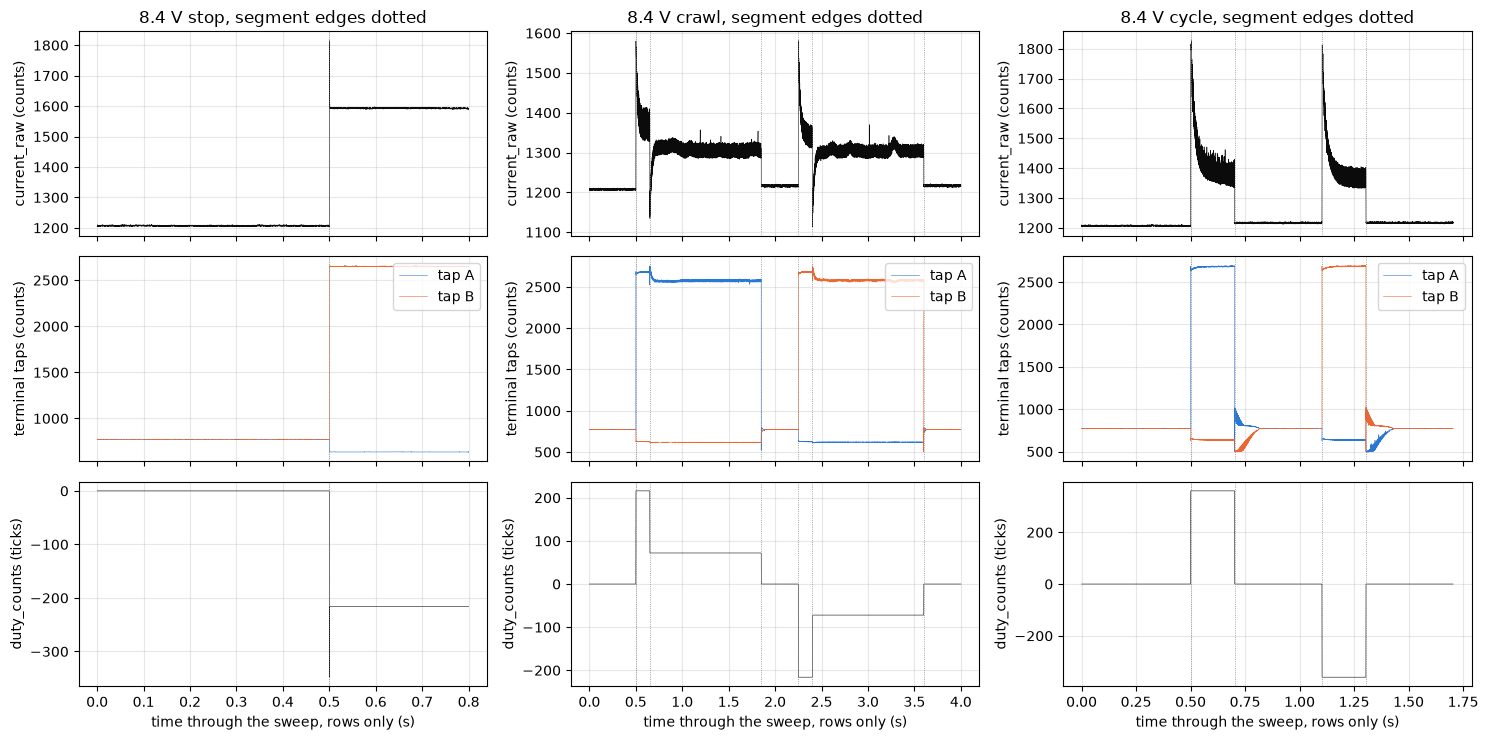

In [13]:
fig, ax = plt.subplots(3, 3, figsize=(15, 7.5), sharex="col")
for j, (what, (df, _, _)) in enumerate(TOP.items()):
    channels = [
        ("current_raw (counts)", [(df["current_raw"], INK)]),
        ("terminal taps (counts)", [(df["vmotor_a"], BLUE, "tap A"),
                                    (df["vmotor_b"], ORANGE, "tap B")]),
        ("duty_counts (ticks)", [(df["duty_counts"], INK)]),
    ]
    figures.sweep_overview(df, FS, channels, axes=ax[:, j])
    ax[0, j].set_title(f"8.4 V {what}, segment edges dotted")
figures.finish(fig)

The stop lap draws a steady current into the stall after a short seek. The crawl's kick lifts the current to the stall level until the rotor breaks away, and the hold then draws a small current with the ripple of a slowly turning motor on it. The cycle's spins start with a current peak that falls as the rotor gathers speed, and each coast drops the current to the open bridge's zero. The rows between segments are not recorded, so the streams sit end to end.

held-5's two windows, the current, the taps and the pot against the rows. The thing to see is that the two windows are the same stall at two rails.

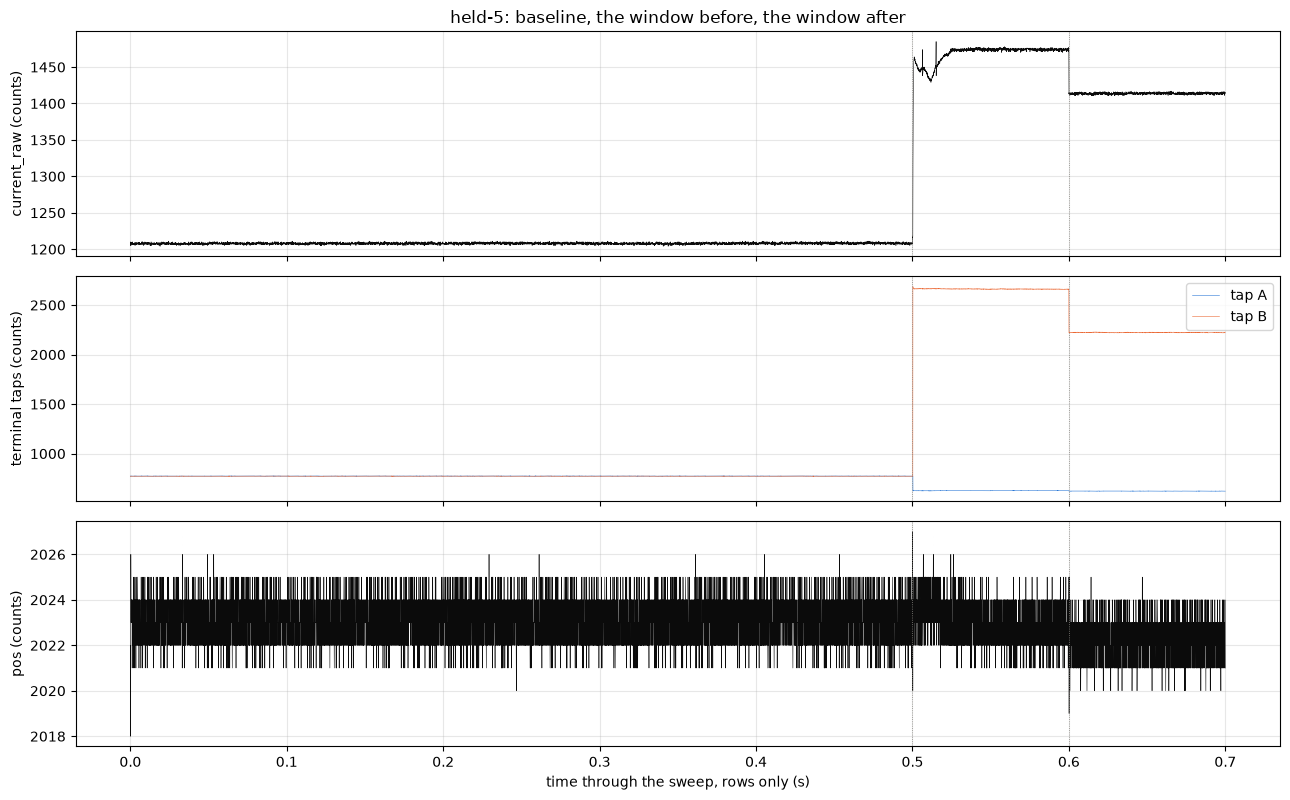

In [14]:
channels = [
    ("current_raw (counts)", [(HELD_DF["current_raw"], INK)]),
    ("terminal taps (counts)", [(HELD_DF["vmotor_a"], BLUE, "tap A"),
                                (HELD_DF["vmotor_b"], ORANGE, "tap B")]),
    ("pos (counts)", [(HELD_DF["pos"], INK)]),
]
fig, ax = figures.sweep_overview(
    HELD_DF, FS, channels,
    title="held-5: baseline, the window before, the window after")
figures.finish(fig)

The baseline, then the 100 ms window before the first DPS step and the 100 ms window after the hold, end to end. The current and the driven tap are lower in the second window, as a lower rail at the same duty gives. The pot stays within a few counts of the lock's seat in both.

## Method

### The chain

Every number goes through the chain the earlier stages built. The board is identified from each sweep's sense block and checked. The current is the crest sample over the sweep's own torque-off zero with current-scale's in-drive offset taken out, $I_\mathrm{crest}$ ("I crest"). The terminal volts at the crest, $V_\mathrm{on}$ ("V on"), are the tap difference through terminal-chain, which is the rail less the bridge's drops while the bridge is on. The effective volts are $V_\mathrm{eff} = D \, V_\mathrm{on}$, with $D$ the applied window over the half period, the duty fraction.

The crest sample is one reading per PWM period near the middle of the on-window. Stage 2 found it reads above the period's mean current by a reading term $G$ ("G") times $V_\mathrm{on}$, 4.29 mA per volt on mg90-b with a meter in series at 20 to 40 % duty. That term is the type's, measured on a bare motor, and here it is a comparison and never a correction carried into a result.

### The rail by route

The rail is read four ways at each level. The DPS's readback is the setpoint echo. The runner's read at the trim is the board's own conversion. The three probes before the rail's sweeps go through terminal-chain's graded rest line, $V = (\mathrm{counts} - 5.95) / 247.54$, and their median is the rail this notebook uses. The same probes through the board's nominal divider, 6400 over 1600 ohm, show what the graded line adds. Under the stop lap the crest tap difference gives $V_\mathrm{on}$, and the rail at rest less $V_\mathrm{on}$ is what the bridge and its feed drop at 0.33 A.

In [15]:
rows = []
for volts, block in LEVELS.groupby("volts_set"):
    raw = block["vbus_raw"].to_numpy(float)    # three probes, torque off
    rest_rail = SCALES.rail_v(raw)             # terminal-chain rest line
    rows.append({
        "volts_set": volts,
        "dps_read": block["dps_read"].iloc[0],     # the setpoint echo
        "vsys_read": block["vsys_read"].iloc[0],   # the runner's read
        "vbus_raw_med": np.median(raw),
        "vbus_raw_range": raw.max() - raw.min(),   # spread of the probes
        "rail_tc_v": np.median(rest_rail),         # the rail, graded line
        "rail_tc_range_mv": (rest_rail.max() - rest_rail.min()) * 1e3,
        "ntc_raw_med": block["ntc_raw"].median()})
RAIL = pd.DataFrame(rows).sort_values("volts_set", ascending=False)
RAIL = RAIL.reset_index(drop=True)

In [16]:
# the board's nominal divider and NTC curve, from the first sweep's board
_, _, BOARD = load(CAPTURE / LEVELS["folder"].iloc[0])
RAIL["rail_nom_v"] = [float(BOARD.rail_v(x)) for x in RAIL["vbus_raw_med"]]
RAIL["ntc_c"] = [float(BOARD.ntc_c_beta(x)) for x in RAIL["ntc_raw_med"]]
RAIL["tc_minus_set_mv"] = (RAIL["rail_tc_v"] - RAIL["volts_set"]) * 1e3
RAIL["tc_minus_vsys_mv"] = (RAIL["rail_tc_v"] - RAIL["vsys_read"]) * 1e3
RAIL["nom_minus_tc_mv"] = (RAIL["rail_nom_v"] - RAIL["rail_tc_v"]) * 1e3
RAIL["diode_v"] = RAIL["dps_read"] - RAIL["vsys_read"]   # the feed diode
RAIL["cap_pct_tc"] = 100 * RATED_V / RAIL["rail_tc_v"]   # the 5 V cap, %
# the cap's slope on the rail times 0.2 V, its step per rail step
RAIL["cap_step_pts_per_0v2"] = (100 * RATED_V / RAIL["rail_tc_v"] ** 2
                                * STEP_V)

The crest tap difference and the current under each stop lap, the held rung from 2 ms in.

In [17]:
def stop_crest(folder):
    """Mean crest volts and amps over a stop lap's rung from SKIP."""
    df, _, _ = load(CAPTURE / folder)
    zero_i, _ = tel.rest_zeros(df)      # the sweep's own zero
    lap = df[df["seg"] == 1]
    ticks = lap["duty_counts"].abs()
    rung = lap[ticks == ticks.iloc[-1]].iloc[SKIP:]   # the held rung
    v_on = volts_on(rung, int(lap["dir"].iloc[0]))
    i = amps(rung["current_raw"], zero_i)
    return {"v_on_crest": v_on.mean(), "v_on_sd": v_on.std(),
            "i_lap_a": i.mean()}


stops = LEVELS[LEVELS["what"] == "stop"]
crest = pd.DataFrame([{"volts_set": r["volts_set"],
                       **stop_crest(r["folder"])}
                      for _, r in stops.iterrows()])
RAIL = RAIL.merge(crest, on="volts_set")
RAIL["rail_minus_von_mv"] = (RAIL["rail_tc_v"] - RAIL["v_on_crest"]) * 1e3
RAIL["ls_loop_drop_mv"] = RAIL["i_lap_a"] * LOW_SIDE_OHM * 1e3
show(RAIL[["volts_set", "vsys_read", "vbus_raw_med", "vbus_raw_range",
           "rail_tc_v", "tc_minus_set_mv", "nom_minus_tc_mv", "diode_v",
           "v_on_crest", "rail_minus_von_mv", "i_lap_a", "cap_pct_tc",
           "cap_step_pts_per_0v2"]], n=None)

,volts_set,vsys_read,vbus_raw_med,vbus_raw_range,rail_tc_v,tc_minus_set_mv,nom_minus_tc_mv,diode_v,v_on_crest,rail_minus_von_mv,i_lap_a,cap_pct_tc,cap_step_pts_per_0v2
0,8.400,8.402,2086.000,6.000,8.403,2.982,0.095,0.248,8.102,301.007,0.335,59.503,1.416
1,8.200,8.188,2035.000,1.000,8.197,-3.048,0.680,0.262,7.910,287.294,0.330,60.998,1.488
2,8.000,7.981,1984.000,7.000,7.991,-9.078,1.266,0.269,7.698,292.643,0.339,62.571,1.566
3,7.800,7.771,1940.000,5.000,7.813,13.171,1.771,0.279,7.510,303.646,0.328,63.995,1.638
4,7.600,7.571,1883.000,9.000,7.583,-17.098,2.425,0.279,7.307,275.418,0.334,65.938,1.739
5,7.400,7.387,1835.000,4.000,7.389,-11.008,2.976,0.263,7.114,275.033,0.327,67.668,1.832
6,7.200,7.177,1786.000,3.000,7.191,-8.958,3.539,0.273,6.912,278.703,0.334,69.531,1.934
7,7.000,6.986,1734.000,1.000,6.981,-19.028,4.135,0.264,6.715,265.978,0.325,71.623,2.052
8,6.800,6.796,1686.000,2.000,6.787,-12.938,4.686,0.254,6.515,272.072,0.329,73.670,2.171
9,6.600,6.590,1638.000,6.000,6.593,-6.849,5.238,0.260,6.312,281.046,0.333,75.836,2.300


### The zero, asleep and awake

The current channel has two zeros. Asleep is the torque-off baseline, the driver asleep, the median of the baseline's second half. Awake is the bridge enabled with its outputs open and the rotor at rest, which every coast gives in its last 100 ms, long after the rotor has stopped. The awake step is the awake mean less the asleep zero of the same sweep. The stop laps have no coast and give only an asleep zero. A pot range of a few counts over the tail says the rotor is at rest, against the same range in the torque-off baseline. The baseline's means by `tick` modulo 16 are the bus-coupling check, a pattern that follows the telemetry frame of 16 rows.

In [18]:
def awake_tails(df, zero_e, rest):
    """The last 100 ms of each coast, the bridge open, rotor at rest."""
    tails = []
    for direction, _, coast_rows in coast.pairs(df):
        if coast.cut_row(coast_rows) is None:
            continue                    # no cut, no coast to read
        tail = coast_rows.iloc[-TAIL_ZERO_ROWS:]
        taps = (tail["vmotor_a"] - tail["vmotor_b"]) * direction
        tails.append({
            "dir": direction,
            "awake": tail["current_raw"].mean(),   # the awake reading
            "awake_sd": tail["current_raw"].std(),
            "tail_pos_range": tail["pos"].max() - tail["pos"].min(),
            "emf_tail_v": (taps - zero_e).mean() * V_PER_COUNT,
            "tap_a_tail": tail["vmotor_a"].mean(),
            "tap_b_tail": tail["vmotor_b"].mean(),
            "tap_a_rest": rest["vmotor_a"].mean(),
            "tap_b_rest": rest["vmotor_b"].mean()})
    return tails

In [19]:
zero_rows = []
for _, r in LEVELS.iterrows():
    df, _, _ = load(CAPTURE / r["folder"])
    zero_i, zero_e = tel.rest_zeros(df)       # the asleep medians
    rest = tel.baseline(df)                   # the torque-off half second
    by16 = rest.groupby(rest["tick"] % 16)["current_raw"].mean()
    sweep = {"k": r["k"], "volts_set": r["volts_set"], "what": r["what"],
             "zero_asleep": zero_i,
             "zero_asleep_mean": rest["current_raw"].mean(),
             "rest_sd": rest["current_raw"].std(),
             "rest_pos_range": rest["pos"].max() - rest["pos"].min(),
             "tick16_spread": by16.max() - by16.min(),
             "zero_e": zero_e}
    tails = awake_tails(df, zero_e, rest)
    for t in tails:
        step = t["awake"] - zero_i            # awake over asleep, counts
        zero_rows.append({**sweep, **t, "step_counts": step,
                          "step_ma": step * A_PER_COUNT * 1e3})
    if not tails:
        zero_rows.append({**sweep, "dir": 0, "awake": np.nan})
ZERO = pd.DataFrame(zero_rows)
ASLEEP = ZERO.drop_duplicates("k")        # one row per sweep
AWAKE = ZERO[ZERO["awake"].notna()]       # one row per coast tail
print(f"{len(ASLEEP)} sweeps, {len(AWAKE)} coast tails; tail pos range "
      f"{AWAKE['tail_pos_range'].min():.0f} to "
      f"{AWAKE['tail_pos_range'].max():.0f} counts, the baselines' "
      f"{ASLEEP['rest_pos_range'].min():.0f} to "
      f"{ASLEEP['rest_pos_range'].max():.0f}")

39 sweeps, 52 coast tails; tail pos range 4 to 7 counts, the baselines' 0 to 7


### The stop lap

Each stop lap drives direction -1 into the low stop for 300 ms. The stream opens on the runner's 29 % seek for a few rows before the lap's own window, so the rung is the rows at the window of the lap's last row, and the settled part starts 40 rows, 2 ms, into it. The lap is accepted as locked if the current's sd is under 4.5 counts and the pot moves under 8 counts.

The apparent resistance is the mean effective volts over the mean crest current, $V_\mathrm{eff} / I_\mathrm{crest}$. The rotor is locked, so there is no back-EMF, and this ratio holds the winding, the brush contacts and any constant brush drop $V_0$ ("V naught") together. Every lap holds 1.5 V effective, so the current is the same at every rail and a line through the laps has no lever on $V_0$. What the rails do vary is $V_\mathrm{on}$, 5.7 to 8.1 V, at the same mean current. A crest over-read of $G \, V_\mathrm{on}$ would make the apparent resistance fall as the rail rises, and the slope of the ratio on the rail is the probe of that term. The same ratio with the type term taken out of the current, $V_\mathrm{eff} / (I_\mathrm{crest} - G \, V_\mathrm{on})$, is kept beside it as the comparison. The first and last 50 ms of the settled lap give its warming.

In [20]:
def stop_arrays(r):
    """The held rung of one stop lap, as arrays over its rows."""
    df, _, board = load(CAPTURE / r["folder"])
    zero_i, _ = tel.rest_zeros(df)      # the sweep's own zero
    lap = df[df["seg"] == 1]
    ticks = lap["duty_counts"].abs()
    rung_ticks = int(ticks.iloc[-1])    # the lap's own window
    rung = lap[ticks == rung_ticks]     # the seek's rows left out
    direction = int(lap["dir"].iloc[0])
    v_on = volts_on(rung, direction)    # crest volts per row
    i_all = amps(rung["current_raw"], zero_i)   # crest amps per row
    duty = rung_ticks / board.pwm_arr   # the duty fraction D
    return {"r": r, "board": board, "rung": rung, "dir": direction,
            "rung_ticks": rung_ticks, "zero_i": zero_i,
            "seek_rows": int((ticks != rung_ticks).sum()),
            "pos_rest": tel.baseline(df)["pos"].median(),
            "v_on": v_on, "i": i_all, "duty": duty,
            "v_eff": duty * v_on,               # effective volts per row
            "i_corr": i_all - G_READ * v_on,    # the type term out
            "i_raw": rung["current_raw"].to_numpy(float)}


def ratio(a, rows):
    """Mean effective volts over mean crest amps over some rows."""
    return a["v_eff"][rows].mean() / a["i"][rows].mean()

In [21]:
def stop_row(a):
    """One lap's row of the stop table."""
    r, rung, settled = a["r"], a["rung"], slice(SKIP, None)
    early, late = ratio(a, EARLY), ratio(a, LATE)
    v_eff = a["v_eff"][settled].mean()
    power = a["v_eff"][settled] * a["i"][settled]   # watts per row
    return {
        "volts_set": r["volts_set"],
        "rail_v": float(SCALES.rail_v(r["vbus_raw"])),
        "dir": a["dir"], "duty_pct": 100 * a["duty"],
        "rung_ticks": a["rung_ticks"], "seek_rows": a["seek_rows"],
        "rows": len(rung), "zero_i": a["zero_i"],
        "i_sd_counts": a["i_raw"][SKIP:].std(),
        "pos_min": rung["pos"].min(), "pos_max": rung["pos"].max(),
        "pos_rest": a["pos_rest"],
        "window_valid_frac": rung["window_valid"].mean(),
        "v_on_v": a["v_on"][settled].mean(),
        "v_on_sd_mv": a["v_on"][settled].std() * 1e3,
        "v_eff_v": v_eff, "i_a": a["i"][settled].mean(),
        "i_corr_a": a["i_corr"][settled].mean(),
        "r_app_ohm": ratio(a, settled),
        "r_corr_ohm": v_eff / a["i_corr"][settled].mean(),
        "r_early_ohm": early, "r_late_ohm": late,
        "warm_pct": 100 * (late / early - 1),
        "joules": power.sum() / FS,
        "ntc_c": float(a["board"].ntc_c_beta(r["ntc_raw"])),
        "t_start": r["t_start"]}

In [22]:
stop_rows, LAP_TRACES = [], {}
for _, r in stops.sort_values("volts_set", ascending=False).iterrows():
    a = stop_arrays(r)
    stop_rows.append(stop_row(a))
    ms = np.arange(len(a["rung"])) / FS * 1e3
    # V_eff / I row by row, rows under 50 mA left out of the ratio
    LAP_TRACES[r["volts_set"]] = (
        ms, a["v_eff"] / np.where(a["i"] > 0.05, a["i"], np.nan))
STOP = pd.DataFrame(stop_rows)
STOP["minutes"] = (STOP["t_start"] - STOP["t_start"].min()) / 60
STOP["locked"] = ((STOP["i_sd_counts"] <= 4.5)
                  & ((STOP["pos_max"] - STOP["pos_min"]) <= 8))
show(STOP[["volts_set", "rail_v", "duty_pct", "seek_rows", "i_sd_counts",
           "pos_min", "pos_max", "v_on_v", "v_eff_v", "i_a", "r_app_ohm",
           "r_corr_ohm", "r_early_ohm", "r_late_ohm", "warm_pct", "ntc_c",
           "locked"]], n=None)
print(f"window_valid fraction at least {STOP['window_valid_frac'].min():.3f}"
      f", rung ticks {STOP['rung_ticks'].min()} to "
      f"{STOP['rung_ticks'].max()} (floors {BOARD.i_window_min_ticks} and "
      f"{BOARD.v_window_min_ticks}), seek rows {STOP['seek_rows'].min()} to "
      f"{STOP['seek_rows'].max()}, {int(STOP['locked'].sum())} of "
      f"{len(STOP)} locked")

,volts_set,rail_v,duty_pct,seek_rows,i_sd_counts,pos_min,pos_max,v_on_v,v_eff_v,i_a,r_app_ohm,r_corr_ohm,r_early_ohm,r_late_ohm,warm_pct,ntc_c,locked
0,8.400,8.395,18.000,5,1.143,1,4,8.102,1.458,0.335,4.347,4.849,4.346,4.353,0.165,25.176,True
1,8.200,8.201,18.000,1,1.104,1,4,7.910,1.424,0.330,4.313,4.807,4.313,4.313,-0.002,25.528,True
2,8.000,8.003,19.000,5,1.211,1,4,7.698,1.463,0.339,4.309,4.773,4.316,4.306,-0.221,25.815,True
3,7.800,7.813,19.000,6,1.347,1,4,7.510,1.427,0.328,4.348,4.821,4.348,4.349,0.042,25.860,True
4,7.600,7.571,20.000,7,1.052,1,4,7.307,1.461,0.334,4.378,4.831,4.377,4.379,0.047,25.815,True
5,7.400,7.381,20.000,6,1.443,1,4,7.114,1.423,0.327,4.357,4.806,4.362,4.362,0.016,25.749,True
6,7.200,7.191,21.000,7,1.090,0,4,6.912,1.452,0.334,4.343,4.766,4.347,4.343,-0.084,25.661,True
7,7.000,6.981,21.000,2,1.272,1,4,6.715,1.410,0.325,4.340,4.762,4.353,4.337,-0.363,25.727,True
8,6.800,6.787,22.000,8,1.166,1,4,6.515,1.433,0.329,4.352,4.755,4.348,4.353,0.104,25.771,True
9,6.600,6.585,23.000,4,1.138,1,4,6.312,1.452,0.333,4.362,4.748,4.364,4.363,-0.021,25.528,True


window_valid fraction at least 1.000, rung ticks 216 to 300 (floors 64 and 93), seek rows 1 to 8, 13 of 13 locked


Every lap passes the locked gate on its current sd, 1.1 to 1.5 counts. The pot reads 0 to 4 counts in every lap, on the ADC's rail. The low stop reads 82 counts on a light seat and the stopper flexes 60 to 84 counts outward under a press, so under the lap the seat sits past the pot's range and the pot is blind to it. The gate's pot test passes because the reading is pinned, and not because the seat is known to hold. The current's sd is what says the rotor is locked.

### The crawl

The crawl's kick is 150 ms at 1.5 V effective, to break the train loose, and its hold about 1.2 s at 0.5 V effective, read over its last 400 ms. The hold's speed is read three ways.

1. The pot. A line through the pot's counts against time over the 400 ms, through the nominal pot slope of 19.8 counts per output degree and the counted 308.05:1 train, in motor revolutions per second.
2. The ripple tach. A brushed motor with $N_r$ ("N r") commutation events per revolution, 3 slots times 2 brushes, puts a ripple at $N_r$ times the revolutions per second on its current. The cycles of the current's ripple are counted over the same 400 ms, seeded at $N_r$ times the pot's speed, and the strongest line between 40 and 1500 Hz is kept beside the count.
3. The coast. The EMF 0.1 to 1 ms past the cut over the type's $K_e$ ("K e"), the back-EMF constant in volts per revolution per second.

The hold is also read in 50 ms bins, the pot's speed and the ripple count bin by bin, the count over the bin with half a bin of margin each side, seeded at the hold's 400 ms speed. The bins after the first 200 ms give each hold's coefficient of variation, the sd over the mean, and a hold kept turning if no bin's pot speed falls under 0.5 rev/s. The kick's breakaway is the first row where the pot has left the kick's first row by more than 3 counts, timed from the drive's first row, with the peak of a 5-row boxcar of the current before it. The reverse kick's stream opens with rows before the drive, and the shaft moves in some of them, so the counts it moved there are kept.

The current the hold should draw is $(V_\mathrm{eff} - K_e \, \omega) / R$, with $\omega$ ("omega") the pot's speed, and the excess of the crest current over it is a closure test of the crest reading at 6 to 8 % duty. The BEMF speed the firmware would form, $(V_\mathrm{eff} - R \, I) / K_e$ with the type $R$ and $K_e$, is read both on the crest current and with the type's reading term taken out.

In [23]:
def ripple_speed(current, seed_rev_s):
    """(rev/s by the seeded count, rev/s by the free peak, cycles)."""
    x = np.asarray(current, float) - current.mean()
    f_free = ripple.line_freq(x, *LOW_BAND)   # the strongest line
    try:
        f_cnt, n = ripple.count_cycles(x, abs(seed_rev_s) * N_R)
    except Exception:
        f_cnt, n = np.nan, 0            # no count in this window
    return f_cnt / N_R, f_free / N_R, n


def coast_cut(coast_rows, direction, zero_e):
    """(EMF just past the cut, its speed over the type Ke, cut row)."""
    cut = coast.cut_row(coast_rows)
    if cut is None:
        return np.nan, np.nan, None
    emf = coast.emf_from_cut(coast_rows, direction, cut, zero_e,
                             v_per_count=V_PER_COUNT)
    e_first = coast.early_emf(emf)      # 0.1 to 1 ms past the cut
    return e_first, e_first / KE, cut

In [24]:
def breakaway(kick, zero_i):
    """(ms to move, peak A before the move, A at the move, rows before
    the drive, counts the shaft moved in those rows)."""
    pre = tel.drive_start(kick)         # rows before the drive starts
    entry = kick["pos"].iloc[pre] - kick["pos"].iloc[0] if pre > 0 else 0
    kick = tel.drive_rows(kick)         # from the first driven row
    pos = kick["pos"].to_numpy(float)
    i = amps(kick["current_raw"], zero_i)
    moved = np.flatnonzero(np.abs(pos - pos[0]) > MOVE_COUNTS)
    if len(moved) == 0:
        return np.nan, i.max(), np.nan, pre, entry
    m = int(moved[0])                   # the first row past the seat
    box = (np.convolve(i[: m + 1], np.ones(5) / 5, mode="same")
           if m >= 5 else i[: m + 1])   # a 5-row boxcar up to the move
    return m / FS * 1e3, float(box.max()), float(i[m]), pre, entry

In [25]:
def hold_bins(held, v_rev, base, direction):
    """Pot speed and ripple count in 50 ms bins down the hold."""
    rows = []
    for j in range(0, len(held) - BIN_ROWS + 1, BIN_ROWS):
        chunk = held.iloc[j:j + BIN_ROWS]
        speed = pot_speed(chunk)[0]
        # the count over the bin with half a bin of margin each side,
        # seeded at the hold's 400 ms pot speed
        lo = max(j - BIN_ROWS // 2, 0)
        wide = held.iloc[lo:j + BIN_ROWS + BIN_ROWS // 2]["current_raw"]
        wide = wide.to_numpy(float)
        try:
            f_bin, _ = ripple.count_cycles(wide - wide.mean(),
                                           abs(v_rev) * N_R)
        except Exception:
            f_bin = np.nan              # no count in this bin
        n = len(rows)
        rows.append({**base, "dir": direction, "bin": n,
                     "t_ms": (n + 0.5) * BIN_ROWS / FS * 1e3,
                     "rev_s": speed, "ripple_rev_s": f_bin / N_R,
                     "pos_mid": chunk["pos"].iloc[len(chunk) // 2]})
    return rows

In [26]:
def crawl_reads(kick, hold, co, zero_i, zero_e, board):
    """The reads of one crawl direction: kick, hold, coast."""
    d = int(kick["dir"].iloc[0])
    hold_ticks = hold["duty_counts"].abs()
    held = hold[hold_ticks == hold_ticks.iloc[-1]]   # the held duty
    tail = held.iloc[-TAIL_ROWS:]                    # its last 400 ms
    v_rev, v_se, cps, pot_noise = pot_speed(tail)
    kick_ticks = kick["duty_counts"].abs().iloc[-1]
    return {"d": d, "held": held, "tail": tail, "v_rev": v_rev,
            "v_se": v_se, "cps": cps, "pot_noise": pot_noise,
            "i_tail": amps(tail["current_raw"], zero_i),
            "v_on": volts_on(tail, d),
            "duty": hold_ticks.iloc[-1] / board.pwm_arr,
            "kick_duty": kick_ticks / board.pwm_arr,
            "brk": breakaway(kick, zero_i),
            "kick_speed": pot_speed(kick.iloc[-1000:])[0],
            "ripple": ripple_speed(tail["current_raw"], v_rev),
            "coast": coast_cut(co, d, zero_e),
            "last50": pot_speed(held.iloc[-1000:])[0]}

In [27]:
def crawl_kick_row(h):
    """The kick's and the ripple's part of a crawl row."""
    ms_move, i_peak, i_move, pre_rows, entry = h["brk"]
    rip_cnt, rip_free, n_cyc = h["ripple"]
    e_cut, w_cut, _ = h["coast"]
    return {"dir": h["d"], "duty_pct": 100 * h["duty"],
            "kick_duty_pct": 100 * h["kick_duty"], "break_ms": ms_move,
            "i_break_peak_a": i_peak, "i_at_move_a": i_move,
            "pre_rows": pre_rows, "entry_counts": entry,
            "kick_end_rev_s": h["kick_speed"],
            "hold_rows": len(h["held"]), "pot_rev_s": h["v_rev"],
            "pot_se": h["v_se"], "pot_counts_s": h["cps"],
            "pot_resid_sd": h["pot_noise"], "ripple_rev_s": rip_cnt,
            "ripple_free_rev_s": rip_free, "ripple_cycles": n_cyc,
            "last50_rev_s": h["last50"], "coast_emf_v": e_cut,
            "coast_rev_s": w_cut}

In [28]:
def crawl_hold_row(h, bins):
    """The hold's part of a crawl row, with its bins."""
    speeds = np.abs([b["rev_s"] for b in bins])        # pot, per bin
    counts = np.array([b["ripple_rev_s"] for b in bins])   # ripple
    late, rlate = speeds[4:], counts[4:]               # after 200 ms
    v_eff = (h["duty"] * h["v_on"]).mean()
    i_mean, v_on = h["i_tail"].mean(), h["v_on"].mean()
    return {"i_hold_a": i_mean, "i_hold_sd_ma": h["i_tail"].std() * 1e3,
            "v_on_v": v_on, "v_eff_v": v_eff,
            "bins_min_rev_s": speeds.min(), "bins_max_rev_s": speeds.max(),
            "bins_cv_pct": (100 * late.std() / late.mean()
                            if late.mean() > 0 else np.nan),
            "rbins_cv_pct": 100 * np.nanstd(rlate) / np.nanmean(rlate),
            "rbins_min_rev_s": np.nanmin(counts),
            "rbins_max_rev_s": np.nanmax(counts),
            "kept_turning": bool((speeds > 0.5).all()),
            "pos_start": h["held"]["pos"].iloc[0],
            "pos_end": h["held"]["pos"].iloc[-1],
            "r_app_hold_ohm": v_eff / i_mean,
            "emf_est_v": v_eff - R_TYPE * i_mean,
            "emf_est_corr_v": v_eff - R_TYPE * (i_mean - G_READ * v_on),
            "pot_abs_rev_s": abs(h["v_rev"]),
            "last50_abs_rev_s": abs(h["last50"])}

### The cycle

The 30 % cycle is read over the spin's last 100 ms. The speed is the ripple count of the current, seeded by the strongest line in the stage 2 band, with the count over the 100 ms before it as the settle check, and the pot's line beside it. The coast is read the way bemf-coast reads a coast. The EMF from the cut, the tap difference signed by the direction less the rest difference, through terminal-chain. Rows where the brush path opens are bridged. The window is the whole ripple cycles closest to 10 ms from 1 ms past the cut, and

$$K_e = \frac{\overline{e}}{\omega} = \frac{\overline{e} \, N_r}{2\pi \, f_r}$$

with $\overline{e}$ the window's mean EMF and $f_r$ its counted ripple frequency, both over the same rows, so the rotor's deceleration inside the window cancels. The BEMF speed of the spin, $(V_\mathrm{eff} - R \, I_\mathrm{crest}) / K_e$ with the type $R$ and $K_e$, is compared with the spin's ripple speed, as read and with the type's reading term out.

In [29]:
def coast_ke(co, d, zero_e):
    """bemf-coast's reduction of one coast: Ke over its window."""
    cut = coast.cut_row(co)
    emf_read = coast.emf_from_cut(co, d, cut, zero_e,
                                  v_per_count=V_PER_COUNT)
    bad = coast.open_rows(emf_read)     # rows the brush path opened
    emf = coast.bridge(emf_read, bad)   # bridged with a line
    stop = coast.stop_row(emf)
    seed = coast.seed_freq(emf)         # the first 10 ms's line
    f_coast, i0, i1, ncyc = ripple.read_window(
        emf, coast.COAST_FROM_ROWS, seed)
    w = 2 * np.pi * f_coast / N_R       # rad/s over the window
    ke = emf[i0:i1].mean() / w          # V s/rad
    return {"coast_rev_s": f_coast / N_R,
            "coast_window_ms": (i1 - i0) / FS * 1e3,
            "coast_cycles": ncyc, "emf_v": emf[i0:i1].mean(),
            "ke_mv_per_rev_s": ke * 2 * np.pi * 1e3,
            "ke_v_s_per_rad": ke, "open_rows": int(bad.sum()),
            "stop_ms": np.nan if stop is None else stop / FS * 1e3,
            "e_first_v": coast.early_emf(emf_read)}

In [30]:
def cycle_row(spin, co, base, zero_i, zero_e, board):
    """One spin and coast of the 30 % cycle."""
    d = int(spin["dir"].iloc[0])
    ticks = spin["duty_counts"].abs()
    driven = spin[ticks == ticks.iloc[-1]]
    duty = ticks.iloc[-1] / board.pwm_arr
    tail = driven.iloc[-CYCLE_TAIL:]                     # last 100 ms
    prev = driven.iloc[-2 * CYCLE_TAIL:-CYCLE_TAIL]      # 100 ms before
    v_rev, v_se, _, _ = pot_speed(tail)
    x = tail["current_raw"].to_numpy(float)
    f_free = ripple.line_freq(x - x.mean(), *ripple.BAND_HZ)
    f_cnt, n = ripple.count_cycles(x - x.mean(), f_free)
    xp = prev["current_raw"].to_numpy(float)
    f_prev, _ = ripple.count_cycles(xp - xp.mean(), f_free)
    i_rows = amps(tail["current_raw"], zero_i)   # crest amps per row
    v_on = volts_on(tail, d)
    v_eff, i_tail = (duty * v_on).mean(), i_rows.mean()
    i_corr = i_tail - G_READ * v_on.mean()   # the type term out
    return {**base, "dir": d, "duty_pct": 100 * duty,
            "spin_ms": len(driven) / FS * 1e3, "pot_rev_s": v_rev,
            "pot_abs_rev_s": abs(v_rev), "pot_se": v_se,
            "ripple_rev_s": f_cnt / N_R, "ripple_prev_rev_s": f_prev / N_R,
            "ripple_free_rev_s": f_free / N_R, "cycles": n,
            "bemf_pred_rev_s": (v_eff - R_TYPE * i_tail) / KE,
            "bemf_pred_corr_rev_s": (v_eff - R_TYPE * i_corr) / KE,
            "i_a": i_tail, "i_sd_ma": i_rows.std() * 1e3,
            "v_on_v": v_on.mean(), "v_eff_v": v_eff,
            "r_app_ohm": v_eff / i_tail, **coast_ke(co, d, zero_e)}

Every crawl and cycle sweep through the reads above, one row per direction.

In [31]:
crawl_rows, cycle_rows, bin_rows = [], [], []
for _, r in LEVELS[LEVELS["what"] != "stop"].iterrows():
    df, _, board = load(CAPTURE / r["folder"])
    zero_i, zero_e = tel.rest_zeros(df)
    base = {"volts_set": r["volts_set"], "k": r["k"],
            "rail_v": float(SCALES.rail_v(r["vbus_raw"]))}
    segs = {int(s): g for s, g in df.groupby("seg")}
    if r["what"] == "crawl":
        for first in (1, 4):            # kick, hold, coast, each way
            h = crawl_reads(segs[first], segs[first + 1],
                            segs[first + 2], zero_i, zero_e, board)
            bins = hold_bins(h["held"], h["v_rev"], base, h["d"])
            bin_rows += bins
            crawl_rows.append({**base, **crawl_kick_row(h),
                               **crawl_hold_row(h, bins)})
    else:
        for first in (1, 3):            # spin, coast, each way
            cycle_rows.append(cycle_row(segs[first], segs[first + 1],
                                        base, zero_i, zero_e, board))
by_rail = dict(by=["volts_set", "dir"], ascending=[False, False])
CRAWL = pd.DataFrame(crawl_rows).sort_values(**by_rail)
CYCLE = pd.DataFrame(cycle_rows).sort_values(**by_rail)
BINS = pd.DataFrame(bin_rows)
print(f"{len(CRAWL)} crawl holds, {len(CYCLE)} spins and coasts, "
      f"{len(BINS)} hold bins")

26 crawl holds, 26 spins and coasts, 599 hold bins


In [32]:
show(CRAWL[["volts_set", "dir", "duty_pct", "v_eff_v", "pot_rev_s",
            "ripple_rev_s", "coast_rev_s", "i_hold_a", "bins_min_rev_s",
            "bins_max_rev_s", "bins_cv_pct", "rbins_cv_pct", "break_ms",
            "i_break_peak_a", "pre_rows", "entry_counts",
            "kept_turning"]], n=None)

,volts_set,dir,duty_pct,v_eff_v,pot_rev_s,ripple_rev_s,coast_rev_s,i_hold_a,bins_min_rev_s,bins_max_rev_s,bins_cv_pct,rbins_cv_pct,break_ms,i_break_peak_a,pre_rows,entry_counts,kept_turning
0,8.400,1,6.000,0.473,34.169,32.541,29.099,0.076,18.191,61.767,27.949,5.989,8.100,0.323,4,-1,True
1,8.400,-1,6.000,0.472,-30.601,31.247,32.786,0.078,19.224,68.624,22.018,6.341,0.050,0.119,2,-5,True
2,8.200,1,6.000,0.461,32.337,31.619,25.839,0.073,17.186,67.555,20.053,6.705,9.300,0.316,5,-1,True
3,8.200,-1,6.000,0.461,-27.786,30.763,26.844,0.076,20.033,61.858,20.483,3.989,0.050,0.129,0,0,True
4,8.000,1,6.000,0.450,29.137,30.461,27.332,0.072,16.649,62.110,26.144,6.665,9.750,0.329,6,0,True
5,8.000,-1,6.000,0.449,-27.390,28.533,23.858,0.076,20.351,72.715,19.331,6.703,0.050,0.117,5,-1,True
6,7.800,1,6.000,0.439,28.484,29.459,31.293,0.070,16.985,63.650,19.457,7.191,8.850,0.314,1,0,True
7,7.800,-1,6.000,0.438,-27.260,28.734,21.817,0.072,19.852,71.563,18.759,5.701,0.050,0.113,2,4,True
8,7.600,1,7.000,0.523,36.892,35.691,28.428,0.073,20.403,67.332,23.339,5.256,10.800,0.328,6,0,True
9,7.600,-1,7.000,0.523,-34.729,35.677,28.855,0.073,24.791,78.296,18.968,2.735,0.300,0.221,9,-1,True


In [33]:
show(CYCLE[["volts_set", "dir", "spin_ms", "pot_rev_s", "ripple_rev_s",
            "ripple_prev_rev_s", "i_a", "v_eff_v", "coast_rev_s",
            "coast_window_ms", "ke_mv_per_rev_s", "open_rows",
            "stop_ms"]], n=None)

,volts_set,dir,spin_ms,pot_rev_s,ripple_rev_s,ripple_prev_rev_s,i_a,v_eff_v,coast_rev_s,coast_window_ms,ke_mv_per_rev_s,open_rows,stop_ms
0,8.400,1,201.900,256.658,249.181,225.769,0.146,2.472,232.537,10.000,7.310,0,111.500
1,8.400,-1,201.550,-248.834,256.796,233.983,0.137,2.473,235.254,9.900,7.292,0,122.450
2,8.200,1,209.950,249.451,242.186,223.379,0.143,2.412,225.538,10.300,7.310,0,113.750
3,8.200,-1,209.550,-241.200,250.373,227.823,0.133,2.415,230.006,10.100,7.289,0,115.350
4,8.000,1,216.600,243.800,237.197,215.204,0.137,2.355,220.444,9.800,7.336,0,116.600
5,8.000,-1,216.700,-233.758,243.872,221.851,0.130,2.356,223.468,9.650,7.315,0,123.000
6,7.800,1,224.950,237.752,231.637,213.266,0.135,2.294,212.848,10.150,7.324,0,115.750
7,7.800,-1,224.750,-228.169,237.031,220.541,0.128,2.295,217.075,9.950,7.316,0,119.200
8,7.600,1,233.800,228.801,224.140,210.461,0.131,2.234,205.435,9.700,7.342,0,109.550
9,7.600,-1,233.900,-220.774,229.768,219.014,0.126,2.237,208.294,9.550,7.318,0,117.500


### The crawl against position

If the hold's bin speeds repeat against the pot's position from rail to rail, the pattern is fixed to the output and not to time. Each rail's bin speeds after the first 100 ms are put on a grid of positions 20 counts apart, between the 5th and 95th percentiles of the direction's positions, keeping only the rails that cover the grid to within 100 counts of each end. The pairwise correlation of the rails' curves says how well the pattern repeats, the ripple count's curves the same way, and the strongest line of the mean curve's spectrum against position gives the pattern's period.

In [34]:
def position_pattern(direction):
    """Bin speeds against pos, per rail, on one grid of positions."""
    g = BINS[(BINS["dir"] == direction) & (BINS["bin"] >= 2)].copy()
    g["rev_s"] = g["rev_s"].abs()
    lo, hi = g["pos_mid"].quantile(0.05), g["pos_mid"].quantile(0.95)
    grid = np.arange(lo, hi, GRID_COUNTS)
    curves, rcurves, kept = [], [], []
    for volts, h in sorted(g.groupby("volts_set"), reverse=True):
        h = h.sort_values("pos_mid")
        if h["pos_mid"].min() > lo + 100 or h["pos_mid"].max() < hi - 100:
            continue                    # the rail misses part of the grid
        curves.append(np.interp(grid, h["pos_mid"], h["rev_s"]))
        rcurves.append(np.interp(grid, h["pos_mid"], h["ripple_rev_s"]))
        kept.append((volts, h))
    return grid, np.array(curves), np.array(rcurves), kept, (lo, hi)

In [35]:
def pattern_stats(grid, cur, rc):
    """Pairwise r of the rails' curves, and the pattern's period."""
    upper = np.triu_indices(len(cur), 1)
    off = np.corrcoef(cur)[upper]       # pot curves, rail against rail
    rfilled = np.nan_to_num(rc, nan=np.nanmean(rc))
    roff = np.corrcoef(rfilled)[upper]  # ripple curves, the same way
    mean_curve = cur.mean(axis=0)
    x = mean_curve - mean_curve.mean()
    spec = np.abs(np.fft.rfft(x * np.hanning(len(x)), n=8 * len(x)))
    freqs = np.fft.rfftfreq(8 * len(x), d=float(GRID_COUNTS))
    k = np.argmax(spec[1:]) + 1         # the strongest line past DC
    return {"rails": len(cur), "r_mean": off.mean(), "r_min": off.min(),
            "r_max": off.max(), "ripple_r_mean": roff.mean(),
            "pattern_sd": mean_curve.std(), "pattern_mean": mean_curve.mean(),
            "rail_sd": cur.std(axis=0).mean(), "period_counts": 1 / freqs[k],
            "mean_curve": mean_curve}


PATTERN = {}
for direction in (1, -1):
    grid, cur, rc, kept, span = position_pattern(direction)
    PATTERN[direction] = {**pattern_stats(grid, cur, rc), "grid": grid,
                          "kept": kept, "span": span}

### held-5

held-5's timeline comes from `segments.csv` and `steps.csv` on the host clock. The two windows are read for their driven rows. The window before the first step opens with 5 rows before the drive and holds the horn seating into the lock for its first 25 ms, so each window is scored over its last 50 ms, its settled current and effective volts, with the whole window's means beside them. The rail each window saw is the capture-1 probes' rail at the DPS level of that moment. A reset of the servo under the hold would drop the drive, and the after window would then open from the zero and rise over the winding's time constant, about 4 rows. So the reset test is whether the after window's first 5 rows sit within 10 mA of its mean. The duty the cap needs to hold 1.0 V effective at each level comes from the same rails.

In [36]:
t0 = HELD_SEGS["t_start"].iloc[0]       # the baseline's start
for _, s in HELD_SEGS.iterrows():
    print(f"seg {s.seg}: duty {s.cmd_duty_q15}, streamed {s.streamed}, "
          f"rows {s.samples}, {s.t_start - t0:.3f} to {s.t_end - t0:.3f} s")
STEPS["took_s"] = STEPS["t_end"] - STEPS["t_start"]   # one DPS step
for _, s in STEPS.iterrows():
    print(f"DPS to {s.volts_set} V: {s.t_start - t0:6.3f} to "
          f"{s.t_end - t0:6.3f} s, the step took {s.took_s:.2f} s")
after_t = HELD_SEGS["t_start"].iloc[3]  # the after window opens
LEVEL_AFTER = STEPS[STEPS["t_start"] <= after_t].iloc[-1]
hold_end = HELD_SEGS["t_end"].iloc[3] - t0
print(f"the after window opened {after_t - LEVEL_AFTER['t_start']:.2f} s "
      f"after the DPS was told {LEVEL_AFTER['volts_set']} V and ended at "
      f"{hold_end:.2f} s, so the last three steps ran after it")
print(f"gaps per segment: {tel.gaps(HELD_DF).to_dict()}, rows dropped "
      f"{HELD_META['rows_dropped']}")

seg 0.0: duty 0.0, streamed 1.0, rows 10000.0, 0.000 to 0.505 s
seg 1.0: duty -3932.0, streamed 1.0, rows 2000.0, 0.522 to 0.626 s
seg 2.0: duty -3932.0, streamed 0.0, rows 0.0, 0.626 to 36.714 s
seg 3.0: duty -3932.0, streamed 1.0, rows 2000.0, 36.714 to 36.818 s
DPS to 8.2 V:  4.909 to  8.762 s, the step took 3.85 s
DPS to 8.0 V:  8.764 to 12.563 s, the step took 3.80 s
DPS to 7.8 V: 12.564 to 16.364 s, the step took 3.80 s
DPS to 7.6 V: 16.367 to 20.166 s, the step took 3.80 s
DPS to 7.4 V: 20.169 to 24.020 s, the step took 3.85 s
DPS to 7.2 V: 24.021 to 27.817 s, the step took 3.80 s
DPS to 7.0 V: 27.818 to 31.623 s, the step took 3.80 s
DPS to 6.8 V: 31.624 to 35.443 s, the step took 3.82 s
DPS to 6.6 V: 35.444 to 39.303 s, the step took 3.86 s
DPS to 6.4 V: 39.304 to 43.110 s, the step took 3.81 s
DPS to 6.2 V: 43.112 to 46.927 s, the step took 3.82 s
DPS to 6.0 V: 46.929 to 50.734 s, the step took 3.81 s
the after window opened 1.27 s after the DPS was told 6.6 V and ended at 36

In [37]:
m5 = pd.read_csv(MANIFEST_5)
held_probes = [p for p in m5[m5["event"] == "probe"]["detail"]
               if "hold" in p or "sag" in p]
for p in held_probes:
    print(p)
start = m5.index[m5["detail"].fillna("").str.contains("sag/held-5")][0]
print("manifest events from the held dataset on:",
      sorted(m5.loc[start:, "event"].unique()))
for seg in (1, 3):                      # the two streamed windows
    g = HELD_DF[HELD_DF["seg"] == seg]
    duties = sorted(int(x) for x in g["cmd_duty_q15"].unique())
    tick_steps = sorted(int(x) for x in np.unique(np.diff(g["tick"])))
    print(f"seg {seg}: cmd_duty_q15 {duties}, "
          f"driven rows {int((g['duty_counts'] != 0).sum())} of {len(g)}, "
          f"tick steps {tick_steps}")

before the hold: pos 2027, ntc_raw 2023, vbus_raw 1243
telemetry/mg90-d__dev-v006-2A-D/sag/held-5/held: pos 2025, ntc_raw 2018, vbus_raw 2083
after the hold: pos 2022, ntc_raw 1996, vbus_raw 1488
manifest events from the held dataset on: ['dataset', 'dps', 'end', 'lock', 'probe', 'prompt', 'rail']
seg 1: cmd_duty_q15 [-3932], driven rows 1995 of 2000, tick steps [1]
seg 3: cmd_duty_q15 [-3932], driven rows 2000 of 2000, tick steps [1]


In [38]:
HELD_ZERO_I, HELD_ZERO_E = tel.rest_zeros(HELD_DF)   # the asleep zero
# the rail at each level, capture-1's probes through the graded line
RAIL_AT = LEVELS.groupby("volts_set")["vbus_raw"].median().map(
    lambda x: float(SCALES.rail_v(x)))


def window_arrays(seg_no):
    """One held-5 window's driven rows, as arrays."""
    g = HELD_DF[HELD_DF["seg"] == seg_no]
    d = int(g["dir"].iloc[0])
    ticks = g["duty_counts"].abs()
    driven, pre = g[ticks > 0], g[ticks == 0]
    duty = ticks.iloc[-1] / HELD_BOARD.pwm_arr
    v_on = volts_on(driven, d)
    return {"seg": seg_no, "d": d, "driven": driven, "pre": pre,
            "duty": duty, "i": amps(driven["current_raw"], HELD_ZERO_I),
            "v_on": v_on, "v_eff": duty * v_on}

In [39]:
def window_row(w):
    """One held-5 window's row, scored over its last 50 ms."""
    i, v_eff, pre = w["i"], w["v_eff"], w["pre"]
    settled = slice(-1000, None)        # the window's last 50 ms
    taps = pre["vmotor_a"] - pre["vmotor_b"]
    return {"seg": w["seg"], "dir": w["d"], "rows": len(w["driven"]),
            "duty_pct": 100 * w["duty"], "pre_rows": len(pre),
            "pre_current_mean": (pre["current_raw"].mean()
                                 if len(pre) else np.nan),
            "pre_tapdiff": taps.mean() if len(pre) else np.nan,
            "i_settled_a": i[settled].mean(),
            "i_settled_sd_ma": i[settled].std() * 1e3,
            "v_eff_settled_v": v_eff[settled].mean(),
            "r_app_settled_ohm": v_eff[settled].mean() / i[settled].mean(),
            "i_first25ms_min_a": i[5:500].min(),
            "i_first25ms_max_a": i[5:500].max(),
            "i_a": i.mean(), "i_sd_ma": i.std() * 1e3,
            "i_first5_a": i[:5].mean(), "i_last5_a": i[-5:].mean(),
            "i_first_row_a": i[0], "v_on_v": w["v_on"].mean(),
            "v_on_sd_mv": w["v_on"].std() * 1e3, "v_eff_v": v_eff.mean(),
            "r_app_ohm": v_eff.mean() / i.mean(),
            "pos_mean": w["driven"]["pos"].mean(),
            "pos_min": w["driven"]["pos"].min(),
            "pos_max": w["driven"]["pos"].max(),
            "window_valid": w["driven"]["window_valid"].mean()}

In [40]:
WINDOWS = pd.DataFrame([window_row(window_arrays(s)) for s in (1, 3)])
level_after = float(LEVEL_AFTER["volts_set"])
WINDOWS["rail_level_v"] = [8.4, level_after]
WINDOWS["rail_tc_v"] = [RAIL_AT[8.4], RAIL_AT[level_after]]
WINDOWS["rail_minus_von_mv"] = (WINDOWS["rail_tc_v"]
                                - WINDOWS["v_on_v"]) * 1e3
WINDOWS["duty_for_1v_pct"] = 100 * HELD_V / WINDOWS["rail_tc_v"]
WINDOWS["cap_5v_pct"] = 100 * RATED_V / WINDOWS["rail_tc_v"]
show(WINDOWS.set_index("seg").T, n=None)

seg,1,3
dir,-1.000,-1.000
rows,1995.000,2000.000
duty_pct,12.000,12.000
pre_rows,5.000,0.000
pre_current_mean,1216.600,NaN
pre_tapdiff,0.800,NaN
i_settled_a,0.230,0.177
i_settled_sd_ma,1.036,0.931
v_eff_settled_v,0.982,0.773
r_app_settled_ohm,4.273,4.370


In [41]:
CAP = pd.DataFrame({"volts_set": RAIL_AT.index,
                    "rail_tc_v": RAIL_AT.values})
CAP = CAP.sort_values("volts_set", ascending=False)
CAP["duty_for_1v_pct"] = 100 * HELD_V / CAP["rail_tc_v"]   # hold 1.0 V
CAP["duty_q15_for_1v"] = CAP["duty_for_1v_pct"] / 100 * 32767
CAP["ticks_for_1v"] = CAP["duty_for_1v_pct"] / 100 * HELD_BOARD.pwm_arr
CAP["cap_5v_pct"] = 100 * RATED_V / CAP["rail_tc_v"]       # the 5 V cap
CAP["step_pts"] = -CAP["duty_for_1v_pct"].diff()    # per 0.2 V step
CAP["cap_step_pts"] = -CAP["cap_5v_pct"].diff()
# the current a 12 % hold would draw at each level on the before
# window's V_eff / I
CAP["i_expected_12pct_a"] = ((0.12 * CAP["rail_tc_v"])
                             / WINDOWS["r_app_ohm"].iloc[0])
show(CAP, n=None)

,volts_set,rail_tc_v,duty_for_1v_pct,duty_q15_for_1v,ticks_for_1v,cap_5v_pct,step_pts,cap_step_pts,i_expected_12pct_a
12,8.400,8.403,11.901,3899.449,142.806,59.503,NaN,NaN,0.231
11,8.200,8.197,12.200,3997.462,146.396,60.998,-0.299,-1.496,0.225
10,8.000,7.991,12.514,4100.528,150.170,62.571,-0.315,-1.573,0.219
9,7.800,7.813,12.799,4193.816,153.587,63.995,-0.285,-1.424,0.214
8,7.600,7.583,13.188,4321.169,158.251,65.938,-0.389,-1.943,0.208
7,7.400,7.389,13.534,4434.570,162.404,67.668,-0.346,-1.730,0.203
6,7.200,7.191,13.906,4556.642,166.874,69.531,-0.373,-1.863,0.197
5,7.000,6.981,14.325,4693.759,171.896,71.623,-0.418,-2.092,0.192
4,6.800,6.787,14.734,4827.863,176.807,73.670,-0.409,-2.046,0.186
3,6.600,6.593,15.167,4969.854,182.007,75.836,-0.433,-2.167,0.181


## The rail as the board reads it

The rail through terminal-chain's graded line against the level, a line through the thirteen rails, the feed diode as the DPS's setpoint less the runner's read, and the duty cap at each end.

In [42]:
FIT_SET = fit_line(RAIL["volts_set"], RAIL["rail_tc_v"])
FIT_VON = fit_line(RAIL["rail_tc_v"], RAIL["v_on_crest"])
resid_mv = " ".join(f"{x * 1e3:+.0f}" for x in FIT_SET["resid"])
print(f"rail on the level: slope {FIT_SET['slope']:.4f} +/- "
      f"{FIT_SET['slope_se']:.4f}, intercept "
      f"{FIT_SET['intercept'] * 1e3:+.0f} +/- "
      f"{FIT_SET['intercept_se'] * 1e3:.0f} mV, rms "
      f"{FIT_SET['rms'] * 1e3:.1f} mV")
print(f"residuals by rail, 8.4 V first (mV): {resid_mv}")
diff = RAIL["tc_minus_set_mv"]
print(f"rail minus level: mean {diff.mean():+.1f} mV, median "
      f"{diff.median():+.1f}, {diff.min():+.0f} to {diff.max():+.0f}")
print(f"three probes per rail spread {RAIL['vbus_raw_range'].min():.0f} to "
      f"{RAIL['vbus_raw_range'].max():.0f} counts, "
      f"{RAIL['rail_tc_range_mv'].min():.0f} to "
      f"{RAIL['rail_tc_range_mv'].max():.0f} mV")
print(f"nominal divider minus graded line "
      f"{RAIL['nom_minus_tc_mv'].min():+.1f} to "
      f"{RAIL['nom_minus_tc_mv'].max():+.1f} mV; the runner's read minus "
      f"the line {(-RAIL['tc_minus_vsys_mv']).min():+.0f} to "
      f"{(-RAIL['tc_minus_vsys_mv']).max():+.0f} mV")
print(f"feed diode (DPS set less the runner's read): mean "
      f"{RAIL['diode_v'].mean():.3f} V, sd {RAIL['diode_v'].std():.3f}, "
      f"{RAIL['diode_v'].min():.3f} to {RAIL['diode_v'].max():.3f}")

rail on the level: slope 1.0050 +/- 0.0030, intercept -44 +/- 22 mV, rms 7.5 mV
residuals by rail, 8.4 V first (mV): +5 +0 -5 +18 -11 -4 -1 -10 -3 +4 -5 +6 +5
rail minus level: mean -8.0 mV, median -9.0, -19 to +13
three probes per rail spread 1 to 9 counts, 4 to 36 mV
nominal divider minus graded line +0.1 to +6.9 mV; the runner's read minus the line -42 to +9 mV
feed diode (DPS set less the runner's read): mean 0.265 V, sd 0.009, 0.248 to 0.279


Each rail by route against the level. The thing to see is how far the graded line sits from the level, and whether the nominal divider or the runner's own read tell a different story.

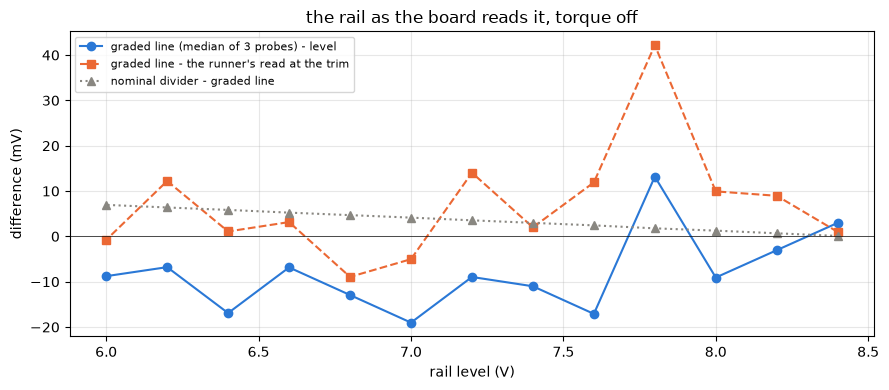

In [43]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(RAIL["volts_set"], RAIL["tc_minus_set_mv"], "o-", color=BLUE,
        label="graded line (median of 3 probes) - level")
ax.plot(RAIL["volts_set"], RAIL["tc_minus_vsys_mv"], "s--", color=ORANGE,
        label="graded line - the runner's read at the trim")
ax.plot(RAIL["volts_set"], RAIL["nom_minus_tc_mv"], "^:", color=MUTED,
        label="nominal divider - graded line")
ax.axhline(0, color=INK, lw=0.5)
ax.legend(fontsize=8)
figures.label(ax, x="rail level (V)", y="difference (mV)",
              title="the rail as the board reads it, torque off")
figures.finish(fig)

The graded line reads the rail within -19 to +13 mV of the level at every rail, 0.3 % or less. A line through the thirteen rails has a slope of 1.0050 +/- 0.0030 and an intercept of -44 +/- 22 mV, and leaves 7.5 mV rms, with no rail standing apart from the band. The three probes of one rail spread 1 to 9 counts, 4 to 36 mV, so one probe is a 10 to 20 mV number, and the scatter about the line is about what the probes alone give. The nominal divider reads 0 to 7 mV over the graded line across the range. Likely, the board reads a still 2S rail to within 20 mV at every state of charge with the stage 1 line. The runner's own read at the trim sits within 15 mV of the line except at 7.8 V, where it reads 42 mV under it. The feed diode drops 0.265 V at rest, sd 0.009.

### The rail under the stop lap

The rail at rest less the crest tap difference under the 0.33 A lap, against the level, with the low-side loop's drop at the same current. The thing to see is how much of the gap the bridge's measured low side accounts for.

rail at rest minus crest V_on under the lap: mean 281.6 mV, sd 13.1, 261 to 304
crest V_on on the rail: slope 0.9910 +/- 0.0043, rms 10.7 mV
I x low-side loop: 97 to 102 mV at 0.330 A


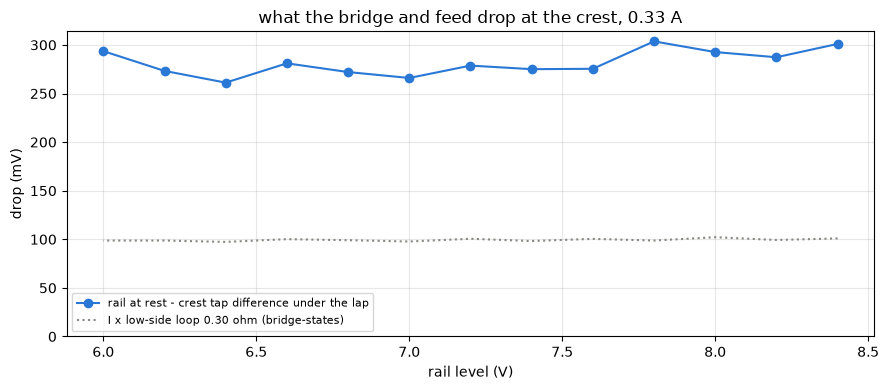

In [44]:
gap = RAIL["rail_minus_von_mv"]
print(f"rail at rest minus crest V_on under the lap: mean {gap.mean():.1f} "
      f"mV, sd {gap.std():.1f}, {gap.min():.0f} to {gap.max():.0f}")
print(f"crest V_on on the rail: slope {FIT_VON['slope']:.4f} +/- "
      f"{FIT_VON['slope_se']:.4f}, rms {FIT_VON['rms'] * 1e3:.1f} mV")
print(f"I x low-side loop: {RAIL['ls_loop_drop_mv'].min():.0f} to "
      f"{RAIL['ls_loop_drop_mv'].max():.0f} mV at "
      f"{RAIL['i_lap_a'].mean():.3f} A")
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(RAIL["volts_set"], gap, "o-", color=BLUE,
        label="rail at rest - crest tap difference under the lap")
ax.plot(RAIL["volts_set"], RAIL["ls_loop_drop_mv"], ":", color=MUTED,
        label=f"I x low-side loop {LOW_SIDE_OHM:.2f} ohm (bridge-states)")
ax.set_ylim(0, None)
ax.legend(fontsize=8)
figures.label(ax, x="rail level (V)", y="drop (mV)",
              title="what the bridge and feed drop at the crest, 0.33 A")
figures.finish(fig)

The rail at rest less the crest $V_\mathrm{on}$ is 261 to 304 mV across the rails, flat with the level. $V_\mathrm{on}$ on the rail has a slope of 0.991 +/- 0.004, so the gap grows 9 +/- 4 mV per volt, a 2 sigma trend. The low-side loop at 0.33 A accounts for about 99 mV. The bridge path as stage 1 measured it predicts 150 to 200 mV, and the 80 to 130 mV left over is open. The feed diode under the lap's mean draw, the probe taken torque off against a loaded lap, and tap A's low excess of 74 mV that terminal-chain found are the candidates. The locked laps of the resistance experiment at 0.74 and 0.83 A separate them, since a gap that grows with the current is a resistance and a gap that does not is an offset.

The duty cap, $100 \times 5 / V_\mathrm{rail}$, and its step per 0.2 V of rail.

In [45]:
cap_hi, cap_lo = RAIL.iloc[0], RAIL.iloc[-1]   # 8.4 V and 6.0 V
ticks = BOARD.pwm_arr / 100             # ticks per point of duty
print(f"5 V cap: {cap_hi['cap_pct_tc']:.1f} % at {cap_hi['volts_set']} V "
      f"to {cap_lo['cap_pct_tc']:.1f} % at {cap_lo['volts_set']} V")
print(f"its step per 0.2 V: {cap_hi['cap_step_pts_per_0v2']:.2f} points "
      f"({cap_hi['cap_step_pts_per_0v2'] * ticks:.0f} ticks) at 8.4 V to "
      f"{cap_lo['cap_step_pts_per_0v2']:.2f} points "
      f"({cap_lo['cap_step_pts_per_0v2'] * ticks:.0f} ticks) at 6.0 V")

5 V cap: 59.5 % at 8.4 V to 83.5 % at 6.0 V
its step per 0.2 V: 1.42 points (17 ticks) at 8.4 V to 2.79 points (33 ticks) at 6.0 V


The cap runs from 59.5 % on a full pack to 83.5 % at the floor, and one 0.2 V step of the rail moves it 1.42 points at the top and 2.79 at the bottom, 17 to 33 ticks of the 1200 tick half period.

## The current zero against the rail

The asleep zero per sweep and the awake step per coast tail, with the lines through both on the rail.

In [46]:
fa = fit_line(ASLEEP["volts_set"], ASLEEP["zero_asleep_mean"])
fw = fit_line(AWAKE["volts_set"], AWAKE["step_counts"])
step = AWAKE["step_counts"]
print(f"asleep: median {ASLEEP['zero_asleep'].median():.1f} counts, "
      f"{ASLEEP['zero_asleep'].min():.0f} to "
      f"{ASLEEP['zero_asleep'].max():.0f} over {len(ASLEEP)} sweeps, mean "
      f"of means {ASLEEP['zero_asleep_mean'].mean():.2f} sd "
      f"{ASLEEP['zero_asleep_mean'].std():.2f}, rest sd "
      f"{ASLEEP['rest_sd'].mean():.2f}")
print(f"tick % 16 spread {ASLEEP['tick16_spread'].mean():.2f} counts "
      f"(at most {ASLEEP['tick16_spread'].max():.2f})")
print(f"asleep on the rail: {fa['slope']:+.2f} +/- {fa['slope_se']:.2f} "
      "counts/V")
print(f"awake step: {step.mean():+.2f} counts "
      f"({AWAKE['step_ma'].mean():+.2f} mA), sd {step.std():.2f}, n "
      f"{len(step)}, se {step.std() / np.sqrt(len(step)):.2f}")
print(f"awake step on the rail: {fw['slope']:+.2f} +/- {fw['slope_se']:.2f}"
      " counts/V")
for what, g in AWAKE.groupby("what"):
    dirs = ", ".join(f"{d:+d} {h['step_counts'].mean():+.2f}"
                     for d, h in g.groupby("dir"))
    print(f"  {what}: {g['step_counts'].mean():+.2f} sd "
          f"{g['step_counts'].std():.2f}, n {len(g)}, by direction {dirs}")
per_rail = AWAKE.groupby("volts_set")["step_counts"].agg(["mean", "std"])
print(f"per rail means {per_rail['mean'].min():.1f} to "
      f"{per_rail['mean'].max():.1f}, sd {per_rail['std'].min():.1f} to "
      f"{per_rail['std'].max():.1f}, n 4 each")

asleep: median 1207.0 counts, 1206 to 1208 over 39 sweeps, mean of means 1207.22 sd 0.40, rest sd 1.01
tick % 16 spread 1.24 counts (at most 1.41)
asleep on the rail: +0.24 +/- 0.08 counts/V
awake step: +9.20 counts (+8.11 mA), sd 0.70, n 52, se 0.10
awake step on the rail: +0.03 +/- 0.13 counts/V
  crawl: +9.14 sd 0.79, n 26, by direction -1 +9.18, +1 +9.10
  cycle: +9.27 sd 0.61, n 26, by direction -1 +9.14, +1 +9.40
per rail means 8.7 to 10.1, sd 0.2 to 1.1, n 4 each


In [47]:
fz = fit_line(ASLEEP["volts_set"], ASLEEP["zero_e"])
taps_a = (AWAKE["tap_a_tail"] - AWAKE["tap_a_rest"]).mean()
taps_b = (AWAKE["tap_b_tail"] - AWAKE["tap_b_rest"]).mean()
emf_mv = AWAKE["emf_tail_v"] * 1e3      # tap difference, tail over rest
print(f"tap difference at rest: {ASLEEP['zero_e'].mean():+.2f} counts sd "
      f"{ASLEEP['zero_e'].std():.2f}, on the rail {fz['slope']:+.3f} +/- "
      f"{fz['slope_se']:.3f} counts/V")
print(f"coast tail over rest: tap A {taps_a:+.2f}, tap B {taps_b:+.2f} "
      f"counts, tap difference {emf_mv.min():+.1f} to {emf_mv.max():+.1f} "
      "mV")

tap difference at rest: -0.62 counts sd 1.23, on the rail +0.055 +/- 0.266 counts/V
coast tail over rest: tap A -0.20, tap B -0.23 counts, tap difference -9.4 to +3.2 mV


The asleep zero per sweep, open markers by the sweep's kind, and the awake reading per coast tail, by direction. The thing to see is whether either moves with the rail, and how far the awake reading sits over the asleep one.

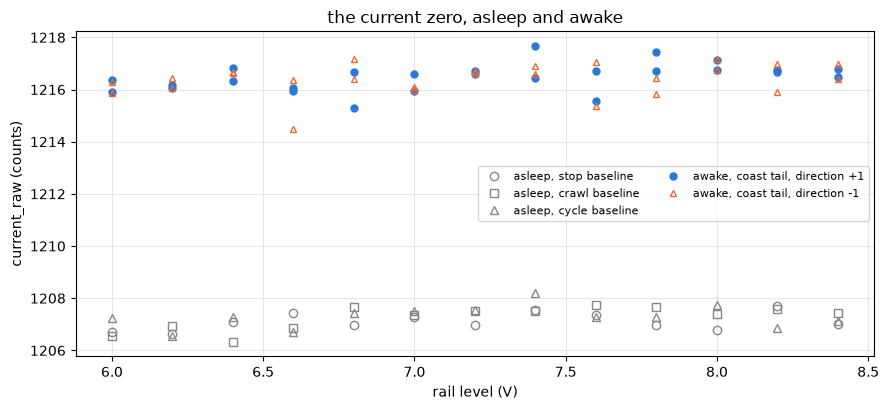

In [48]:
fig, ax = plt.subplots(figsize=(9, 4.2))
for what, mark in (("stop", "o"), ("crawl", "s"), ("cycle", "^")):
    g = ASLEEP[ASLEEP["what"] == what]
    ax.plot(g["volts_set"], g["zero_asleep_mean"], mark, color=MUTED,
            mfc="none", label=f"asleep, {what} baseline")
for d, color in ((1, BLUE), (-1, ORANGE)):
    g = AWAKE[AWAKE["dir"] == d]
    ax.plot(g["volts_set"], g["awake"], ms=5,
            label=f"awake, coast tail, direction {d:+d}",
            **figures.direction_style(d, color))
ax.legend(fontsize=8, ncol=2)
figures.label(ax, x="rail level (V)", y="current_raw (counts)",
              title="the current zero, asleep and awake")
figures.finish(fig)

The asleep zero reads 1207 counts, 1206 to 1208 over the 39 sweeps, with a sd of the sweep means of 0.40 count. Its trend on the rail is +0.24 +/- 0.08 counts per volt, under one count over the whole range, which is reported and changes no number. The bus-coupling check passes, with the 16 tick-phase means within 1.4 counts of each other.

The awake reading sits +9.20 counts over the asleep zero, +8.11 mA, sd 0.70, over 52 tails, the crawl's and the cycle's alike and both directions within 0.3 count. Its trend on the rail is +0.03 +/- 0.13 counts per volt, flat. The tails are at rest, with a pot range of 4 to 7 counts against 0 to 7 in the torque-off baselines, the taps about 0.2 count under their rest bias, and the tap difference -9 to +3 mV from rest. held-5's 5 rows before its drive read +8.6 counts on another day. Likely, the tracker needs no rail term over 2S, and the awake bridge adds a constant 8 mA.

Stage 2's bemf-coast found the open bridge's zero growing with the rail, from about 2 to 8 mA between 3.7 and 7.4 V on the bare motors. This servo's step is flat at 8.1 mA from 6.0 to 8.4 V. A step that saturates near 7 V and a difference of board state between the sittings both fit the two. The same coast-tail read on this servo's 3.7 and 5.0 V sweeps of the ladder experiment separates them.

## R from the stop laps

The apparent resistance of the thirteen laps, as read and with the type's reading term out, each against the rail.

In [49]:
FIT_R = {}
for key in ("r_app_ohm", "r_corr_ohm", "r_early_ohm"):
    f = fit_line(STOP["rail_v"], STOP[key])
    FIT_R[key] = f
    x = STOP[key]
    print(f"{key}: mean {x.mean():.4f} sd {x.std():.4f} "
          f"({100 * x.std() / x.mean():.2f} %), {x.min():.3f} to "
          f"{x.max():.3f}, on the rail {f['slope']:+.4f} +/- "
          f"{f['slope_se']:.4f} ohm/V ({f['slope'] / f['slope_se']:+.1f} "
          "sigma)")
I_LAP, V_EFF_LAP = STOP["i_a"].mean(), STOP["v_eff_v"].mean()
print(f"V_eff {V_EFF_LAP:.4f} V sd {STOP['v_eff_v'].std():.4f}, current "
      f"{I_LAP:.4f} A sd {STOP['i_a'].std():.4f} "
      f"({100 * STOP['i_a'].std() / I_LAP:.2f} %)")
f = fit_line(STOP["i_a"], STOP["v_eff_v"])
print(f"V_eff on I across the laps, no lever: R {f['slope']:.2f} +/- "
      f"{f['slope_se']:.2f} ohm, V0 {f['intercept']:+.2f} +/- "
      f"{f['intercept_se']:.2f} V")

r_app_ohm: mean 4.3440 sd 0.0189 (0.43 %), 4.309 to 4.378, on the rail -0.0055 +/- 0.0071 ohm/V (-0.8 sigma)
r_corr_ohm: mean 4.7722 sd 0.0496 (1.04 %), 4.691 to 4.849, on the rail +0.0568 +/- 0.0085 ohm/V (+6.7 sigma)
r_early_ohm: mean 4.3438 sd 0.0189 (0.44 %), 4.313 to 4.377, on the rail -0.0015 +/- 0.0073 ohm/V (-0.2 sigma)
V_eff 1.4351 V sd 0.0195, current 0.3304 A sd 0.0046 (1.38 %)
V_eff on I across the laps, no lever: R 4.06 +/- 0.41 ohm, V0 +0.09 +/- 0.13 V


The reading term as a rail slope. With $I_\mathrm{crest} = I + G \, V_\mathrm{on}$ at a fixed mean $I$, the apparent resistance $V_\mathrm{eff} / I_\mathrm{crest}$ falls with the rail at about $-R^2 G / V_\mathrm{eff}$ ohm per volt. The measured slope, read back through the same relation, gives the term the locked lap carries.

In [50]:
R0 = STOP["r_corr_ohm"].mean()         # R with the type term out
PRED = -R0 ** 2 * G_READ / V_EFF_LAP    # ohm/V the type term predicts
per = -V_EFF_LAP / R0 ** 2              # A/V of term per ohm/V of slope
G_LOCKED = FIT_R["r_app_ohm"]["slope"] * per          # A/V, measured
G_LOCKED_SE = FIT_R["r_app_ohm"]["slope_se"] * -per
print(f"type term {G_READ * 1e3:.2f} mA/V predicts {PRED:+.4f} ohm/V at R "
      f"{R0:.3f}, V_eff {V_EFF_LAP:.3f}")
print(f"its over-read at 8.4 V: {G_READ * 8.4 * 1e3:.1f} mA, "
      f"{100 * G_READ * 8.4 / I_LAP:.1f} % of the lap current, at 6.0 V "
      f"{100 * G_READ * 6.0 / I_LAP:.1f} %")
print(f"measured slope implies {G_LOCKED * 1e3:.2f} +/- "
      f"{G_LOCKED_SE * 1e3:.2f} mA/V, under "
      f"{(G_LOCKED + 2 * G_LOCKED_SE) * 1e3:.2f} mA/V at 2 sigma")
print(f"with the type V0 {V0_TYPE:.2f} V out: R "
      f"{(V_EFF_LAP - V0_TYPE) / I_LAP:.2f} ohm on the crest current, "
      f"{(V_EFF_LAP - V0_TYPE) / STOP['i_corr_a'].mean():.2f} on the "
      "type-corrected current")

type term 4.29 mA/V predicts -0.0680 ohm/V at R 4.772, V_eff 1.435
its over-read at 8.4 V: 36.0 mA, 10.9 % of the lap current, at 6.0 V 7.8 %
measured slope implies 0.35 +/- 0.45 mA/V, under 1.24 mA/V at 2 sigma
with the type V0 0.06 V out: R 4.16 ohm on the crest current, 4.57 on the type-corrected current


Each lap's $V_\mathrm{eff} / I_\mathrm{crest}$ through its 300 ms, a 10 ms boxcar, one trace per rail, light to dark from 8.4 V down. The thing to see is whether a lap drifts as it warms, and whether the rails sit in order.

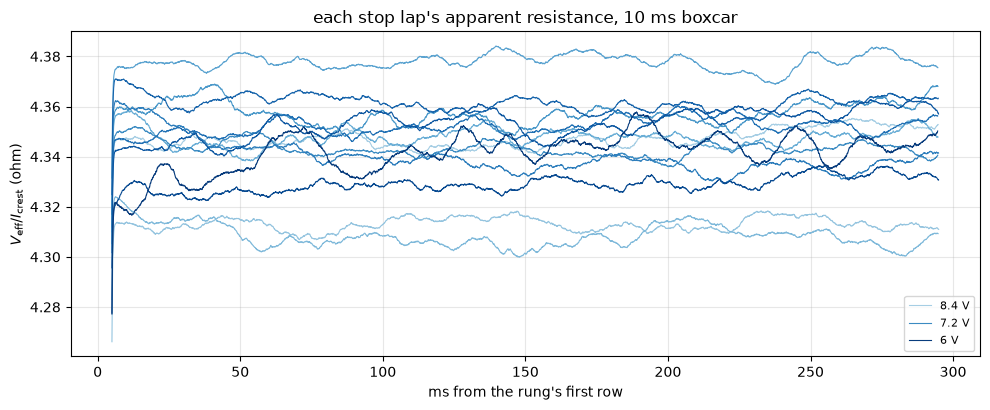

In [51]:
fig, ax = plt.subplots(figsize=(10, 4.2))
box = 200                               # rows, a 10 ms boxcar
colors = figures.shades("Blues", len(LAP_TRACES))
for (volts, (ms, r)), color in zip(sorted(LAP_TRACES.items(),
                                          reverse=True), colors):
    smooth = np.convolve(r, np.ones(box) / box, mode="valid")
    t = ms[box // 2: box // 2 + len(smooth)]
    ax.plot(t, smooth, lw=0.8, color=color,
            label=f"{volts:g} V" if volts in (8.4, 7.2, 6.0) else None)
ax.legend(fontsize=8)
figures.label(ax, x="ms from the rung's first row",
              y=r"$V_\mathrm{eff} / I_\mathrm{crest}$ (ohm)",
              title="each stop lap's apparent resistance, 10 ms boxcar")
figures.finish(fig)

The laps are flat through the 300 ms and sit within about 0.07 ohm of each other with no order by rail. The first few milliseconds after the seek are left out of every number below by the 2 ms skip.

R per rail, as read and with the type's reading term out, with the lines through both and the type's locked value. The thing to see is which of the two stays flat with the rail.

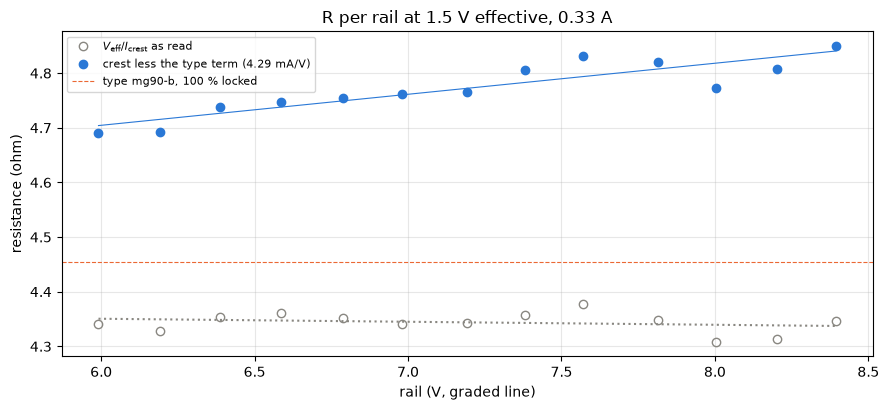

In [52]:
fig, ax = plt.subplots(figsize=(9, 4.2))
fr, fc = FIT_R["r_app_ohm"], FIT_R["r_corr_ohm"]
xx = np.array([STOP["rail_v"].min(), STOP["rail_v"].max()])
ax.plot(STOP["rail_v"], STOP["r_app_ohm"], "o", color=MUTED, mfc="none",
        label=r"$V_\mathrm{eff} / I_\mathrm{crest}$ as read")
ax.plot(xx, fr["slope"] * xx + fr["intercept"], ":", color=MUTED)
ax.plot(STOP["rail_v"], STOP["r_corr_ohm"], "o", color=BLUE,
        label=f"crest less the type term ({G_READ * 1e3:.2f} mA/V)")
ax.plot(xx, fc["slope"] * xx + fc["intercept"], "-", color=BLUE, lw=0.8)
ax.axhline(R_TYPE, color=ORANGE, lw=0.8, ls="--",
           label=f"type {TYPE_KEY}, 100 % locked")
ax.legend(fontsize=8)
figures.label(ax, x="rail (V, graded line)", y="resistance (ohm)",
              title="R per rail at 1.5 V effective, 0.33 A")
figures.finish(fig)

As read, the laps give $V_\mathrm{eff} / I_\mathrm{crest}$ = 4.344 ohm, sd 0.019 (0.43 %), 4.309 to 4.378, with a slope on the rail of -0.0055 +/- 0.0071 ohm per volt, 0.8 sigma, flat. The type term predicts -0.068 ohm per volt. The measured slope implies a term of 0.35 +/- 0.45 mA per volt on the locked lap, under 1.3 mA per volt at 2 sigma, against the type's 4.29. With the type term subtracted the resistance rises +0.057 +/- 0.009 ohm per volt with the rail, 6.7 sigma. The leading reading is that the locked lap at 18 to 25 % duty reads close to its mean, and the type term does not describe it. A constant crest offset that does not depend on the rail is the alternative, and it is invisible here. A lap at two currents on one rail separates them.

$R$ and $V_0$ do not separate in these laps. Every lap runs at the same 0.33 A, so a line of $V_\mathrm{eff}$ on $I$ across the laps has no lever, and its 4.1 +/- 0.4 ohm and +0.09 +/- 0.13 V are not a result. With the type's 0.06 V brush drop taken out, the crest current gives 4.16 ohm. So the result carries the ratio as read, 4.344 ohm, as a candidate with $V_0$ and any constant crest offset folded in, at one commutator angle, since the seat never moved.

Against the type, mg90-b reads 4.455 ohm, 4.384 to 4.531, at 0.78 A and 100 % duty, and mg90-c 4.402. mg90-d's 4.344 sits under both. The type was read at 100 % with no switching and at more than twice this current, so the two differ in the reading term, the brush contact's current and the copper's temperature, and none of the three is separated here.

The laps in the order they ran, with the board's NTC. The thing to see is whether the resistance follows the time or the temperature.

type-corrected R on minutes: -3.2 +/- 0.5 mohm/min over 42 min; on the NTC +75 +/- 59 mohm/C, copper 19 mohm/C; NTC 25.2 to 25.9 C


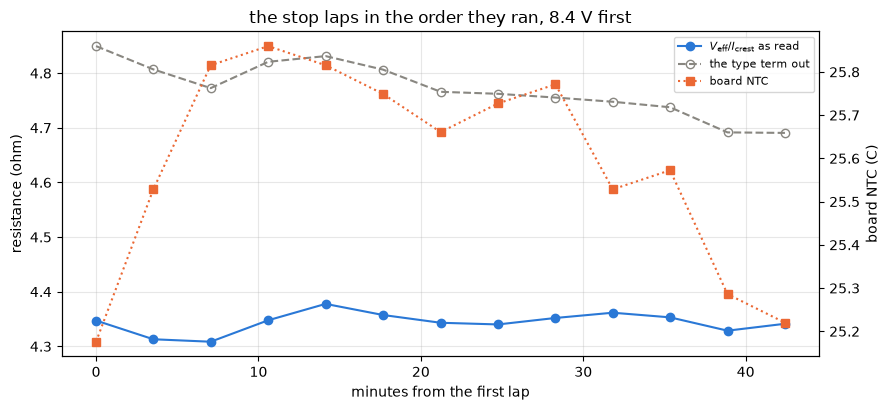

In [53]:
ft = fit_line(STOP["minutes"], STOP["r_corr_ohm"])
fn = fit_line(STOP["ntc_c"], STOP["r_corr_ohm"])
print(f"type-corrected R on minutes: {ft['slope'] * 1e3:+.1f} +/- "
      f"{ft['slope_se'] * 1e3:.1f} mohm/min over "
      f"{STOP['minutes'].max():.0f} min; on the NTC "
      f"{fn['slope'] * 1e3:+.0f} +/- {fn['slope_se'] * 1e3:.0f} mohm/C, "
      f"copper {R0 * COPPER_PCT_PER_C * 10:.0f} mohm/C; NTC "
      f"{STOP['ntc_c'].min():.1f} to {STOP['ntc_c'].max():.1f} C")
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(STOP["minutes"], STOP["r_app_ohm"], "o-", color=BLUE,
        label=r"$V_\mathrm{eff} / I_\mathrm{crest}$ as read")
ax.plot(STOP["minutes"], STOP["r_corr_ohm"], "o--", color=MUTED,
        mfc="none", label="the type term out")
twin = ax.twinx()
twin.plot(STOP["minutes"], STOP["ntc_c"], "s:", color=ORANGE,
          label="board NTC")
twin.set_ylabel("board NTC (C)")
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = twin.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, fontsize=8)
figures.label(ax, x="minutes from the first lap", y="resistance (ohm)",
              title="the stop laps in the order they ran, 8.4 V first")
figures.finish(fig)

The board's NTC moves 25.2 to 25.9 C over the 42 minutes, which gives no lever on temperature. The type-corrected column falls 3.2 +/- 0.5 mohm per minute, which is the rail falling with time through the type term, since the laps ran from 8.4 V down. The as-read column has no trend to speak of.

The warming within a lap, the last 50 ms over the first 50 ms after the skip, against what the type's locked laps predict for the same energy.

In [54]:
warm = STOP["warm_pct"]
joules = STOP["joules"].mean()
predicted = WARM_TYPE * joules * 0.83   # the share between the windows
print(f"within-lap warming {warm.mean():+.2f} % sd {warm.std():.2f}, se "
      f"{warm.std() / np.sqrt(len(warm)):.2f}, over {joules:.3f} J a lap")
print(f"the type's {WARM_TYPE:.2f} %/J predicts {predicted:+.2f} %")

within-lap warming +0.05 % sd 0.20, se 0.06, over 0.141 J a lap
the type's 2.86 %/J predicts +0.34 %


A lap warms +0.05 +/- 0.06 % from its first to its last 50 ms, against +0.34 % from the type's 2.86 % per joule over the same 0.14 J. The gap is open. The type's figure comes from 0.78 to 0.85 A laps with a contact term that bends with the current, a crest transient relaxing through the lap would hide a rise, and the copper's share of the reading is smaller at 0.33 A. Laps at 0.33 and 0.75 A on one seat, read as the rise per joule, separate them.

## The crawl against the rail

The hold's speed, current and effective volts by direction, with their lines on the rail.

In [55]:
speed = CRAWL["pot_abs_rev_s"]
print(f"kept turning: {int(CRAWL['kept_turning'].sum())} of {len(CRAWL)}; "
      f"|pot| {speed.min():.1f} to {speed.max():.1f} rev/s, mean "
      f"{speed.mean():.1f} sd {speed.std():.1f}; current "
      f"{CRAWL['i_hold_a'].mean() * 1e3:.1f} mA sd "
      f"{CRAWL['i_hold_a'].std() * 1e3:.1f}; V_eff "
      f"{CRAWL['v_eff_v'].min():.3f} to {CRAWL['v_eff_v'].max():.3f} V")
CRAWL_FIT = {}
for d, g in CRAWL.groupby("dir"):
    f = fit_line(g["rail_v"], g["pot_rev_s"])
    fi = fit_line(g["rail_v"], g["i_hold_a"] * 1e3)
    CRAWL_FIT[d] = {"speed": f, "current": fi}
    print(f"  {d:+d}: {g['pot_rev_s'].mean():+.1f} sd "
          f"{g['pot_rev_s'].std():.1f} rev/s, on the rail "
          f"{f['slope']:+.1f} +/- {f['slope_se']:.1f} rev/s per V; current "
          f"{g['i_hold_a'].mean() * 1e3:.1f} mA, on the rail "
          f"{fi['slope']:+.1f} +/- {fi['slope_se']:.1f} mA/V")
slopes = [CRAWL_FIT[d]["current"] for d in (1, -1)]
I_PER_V = np.mean([s["slope"] for s in slopes])     # mA/V, both ways
I_PER_V_SE = np.hypot(*[s["slope_se"] for s in slopes]) / 2
print(f"current on the rail, both ways: {I_PER_V:+.1f} +/- "
      f"{I_PER_V_SE:.1f} mA/V")
rel = (CRAWL["ripple_rev_s"] / CRAWL["pot_abs_rev_s"] - 1) * 100
print(f"ripple count over pot - 1: {rel.mean():+.1f} % sd {rel.std():.1f}"
      f" (n {rel.notna().sum()})")
for d, g in CRAWL.groupby("dir"):
    c = (g["coast_rev_s"] / g["pot_abs_rev_s"] - 1) * 100
    print(f"  coast EMF over type Ke against pot, {d:+d}: {c.mean():+.1f} "
          f"% sd {c.std():.1f}")

kept turning: 26 of 26; |pot| 27.3 to 36.9 rev/s, mean 31.4 sd 2.8; current 71.2 mA sd 3.3; V_eff 0.438 to 0.523 V
  -1: -30.5 sd 2.5 rev/s, on the rail +0.6 +/- 0.9 rev/s per V; current 72.1 mA, on the rail +3.8 +/- 0.5 mA/V
  +1: +32.3 sd 3.0 rev/s, on the rail -0.4 +/- 1.1 rev/s per V; current 70.2 mA, on the rail +3.4 +/- 0.6 mA/V
current on the rail, both ways: +3.6 +/- 0.4 mA/V
ripple count over pot - 1: +2.4 % sd 4.7 (n 26)
  coast EMF over type Ke against pot, -1: -6.1 % sd 9.5
  coast EMF over type Ke against pot, +1: -10.9 % sd 11.6


The hold's speed by the three routes, against the rail. The thing to see is whether the speed stays put while the rail falls at a held $V_\mathrm{eff}$, and whether the routes agree.

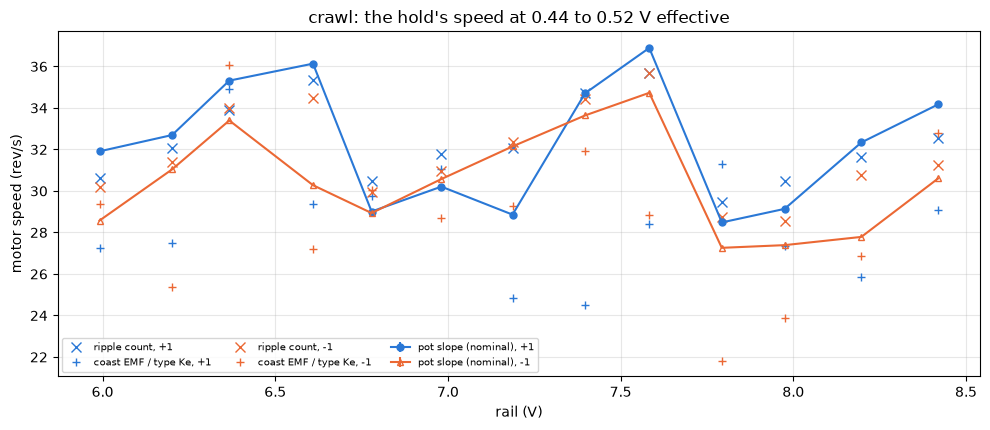

In [56]:
fig, ax = plt.subplots(figsize=(10, 4.4))
for d, color in ((1, BLUE), (-1, ORANGE)):
    g = CRAWL[CRAWL["dir"] == d]
    style = {**figures.direction_style(d, color), "ls": "-"}
    ax.errorbar(g["rail_v"], g["pot_rev_s"].abs(), yerr=g["pot_se"], ms=5,
                label=f"pot slope (nominal), {d:+d}", **style)
    ax.plot(g["rail_v"], g["ripple_rev_s"], ls="none", ms=7, marker="x",
            color=color, label=f"ripple count, {d:+d}")
    ax.plot(g["rail_v"], g["coast_rev_s"], ls="none", ms=6, marker="+",
            color=color, label=f"coast EMF / type Ke, {d:+d}")
ax.legend(fontsize=7, ncol=3)
figures.label(ax, x="rail (V)", y="motor speed (rev/s)",
              title="crawl: the hold's speed at 0.44 to 0.52 V effective")
figures.finish(fig)

Every hold kept turning, 26 of 26, in one session. The pot reads 31.4 rev/s, sd 2.8, 27 to 37, at the motor, about 6 degrees per second at the horn, and the trend on the rail is within 1 sigma either way. The ripple count reads the same speed, +2.4 % over the pot, sd 4.7. The coast's EMF at 1 ms past the cut over the type $K_e$ reads 6 to 11 % under the pot, sd about 10 %, so it is not a crawl tach. The effective volts step with the whole-percent duty, 6 % to 8 % on the rails, which makes the 0.44 to 0.52 V spread, and the speed follows those steps.

The hold's current against the rail. The thing to see is the current rising with the rail at about the same speed and effective volts.

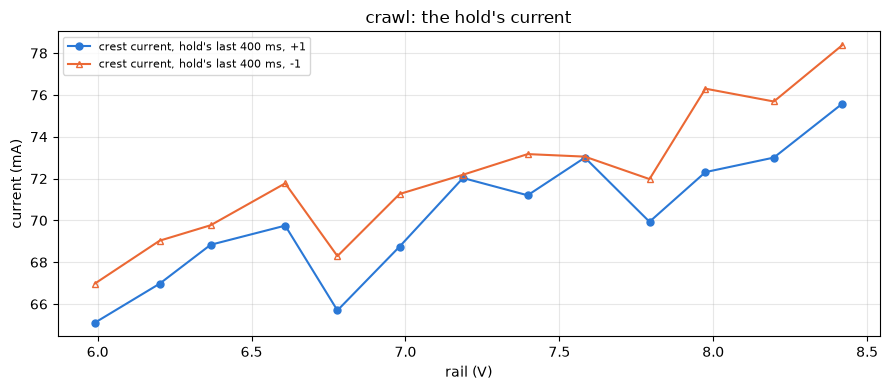

In [57]:
fig, ax = plt.subplots(figsize=(9, 4))
for d, color in ((1, BLUE), (-1, ORANGE)):
    g = CRAWL[CRAWL["dir"] == d]
    style = {**figures.direction_style(d, color), "ls": "-"}
    ax.plot(g["rail_v"], g["i_hold_a"] * 1e3, ms=5,
            label=f"crest current, hold's last 400 ms, {d:+d}", **style)
ax.legend(fontsize=8)
figures.label(ax, x="rail (V)", y="current (mA)",
              title="crawl: the hold's current")
figures.finish(fig)

The current is 71.2 mA, sd 3.3, and rises +3.6 +/- 0.4 mA per volt of rail at a near-constant speed and $V_\mathrm{eff}$. The closure says how much of it the motor draws.

In [58]:
R_LAP = STOP["r_app_ohm"].mean()       # this servo's stop-lap ratio
CLOSURE = {}
for name, r_ohm in (("R_type", R_TYPE), ("R_lap", R_LAP),
                    ("R_lap_corr", STOP["r_corr_ohm"].mean())):
    # the current the motor should draw at the pot's speed
    i_true = (CRAWL["v_eff_v"] - KE * CRAWL["pot_abs_rev_s"]) / r_ohm
    excess = (CRAWL["i_hold_a"] - i_true) * 1e3   # mA over it
    f = fit_line(CRAWL["v_on_v"], excess)
    CLOSURE[name] = excess
    print(f"excess over (V_eff - Ke w_pot)/{name} ({r_ohm:.3f} ohm): "
          f"{excess.mean():+.1f} mA sd {excess.std():.1f}; on V_on "
          f"{f['slope']:+.1f} +/- {f['slope_se']:.1f} mA/V, intercept "
          f"{f['intercept']:+.0f} +/- {f['intercept_se']:.0f} mA")
true_ma = (CRAWL["i_hold_a"].mean() * 1e3
           - np.array([CLOSURE[k].mean() for k in CLOSURE]))
print(f"so the motor's current is {true_ma.min():.0f} to "
      f"{true_ma.max():.0f} mA")
emf, emf_c = CRAWL["emf_est_v"].mean(), CRAWL["emf_est_corr_v"].mean()
pot = CRAWL["pot_abs_rev_s"].mean()
for name, e in (("crest current", emf), ("type term out", emf_c)):
    print(f"BEMF speed on the {name}: {e * 1e3:.0f} mV, {e / KE:.1f} "
          f"rev/s, {(e / KE / pot - 1) * 100:+.0f} % on the pot's "
          f"{pot:.1f}")

excess over (V_eff - Ke w_pot)/R_type (4.455 ohm): +14.3 mA sd 5.2; on V_on +6.6 +/- 1.1 mA/V, intercept -31 +/- 8 mA
excess over (V_eff - Ke w_pot)/R_lap (4.344 ohm): +12.9 mA sd 5.2; on V_on +6.6 +/- 1.1 mA/V, intercept -33 +/- 8 mA
excess over (V_eff - Ke w_pot)/R_lap_corr (4.772 ohm): +18.1 mA sd 5.0; on V_on +6.4 +/- 1.0 mA/V, intercept -27 +/- 7 mA
so the motor's current is 53 to 58 mA
BEMF speed on the crest current: 167 mV, 22.7 rev/s, -28 % on the pot's 31.4
BEMF speed on the type term out: 300 mV, 40.8 rev/s, +30 % on the pot's 31.4


With the type $K_e$, 0.2 % from this motor's, and the stop lap's or the type's $R$, the motor should draw 53 to 58 mA at the pot's speed, so the crest current carries +13 to +18 mA, 20 to 30 %, over it at 6 to 8 % duty. The excess grows on $V_\mathrm{on}$ at +6.4 to +6.6 mA per volt with an intercept of -27 to -33 mA, which is not a line through zero. Rail and duty move together in this capture, and the window is 72 to 96 ticks long, at the shunt's settle, so a window-length over-read and a term in $V_\mathrm{on}$ are not separated here.

The BEMF speed as the firmware would form it reads -28 % on the crest current and +30 % with the type term out, with the truth between them. Either way the speed is 8 to 10 rev/s off, about 1.5 to 2 degrees per second at the horn.

The kick's breakaway in direction +1, the peak current before the pot left its seat by 3 counts and the time it took. The thing to see is whether the current had to climb to a threshold before the train moved.

+1: moved 9.6 ms sd 0.7 after the drive started, peak 318 mA sd 6 before the move, 227 mA at the move row; kick end 132 rev/s
-1: rows before the drive [2, 0, 5, 2, 9, 2, 0, 4, 4, 0, 0, 6, 4], counts moved in them [-5, 0, -1, 4, -1, -11, 0, -13, -5, 0, 0, -6, -3]; kick end -157 rev/s


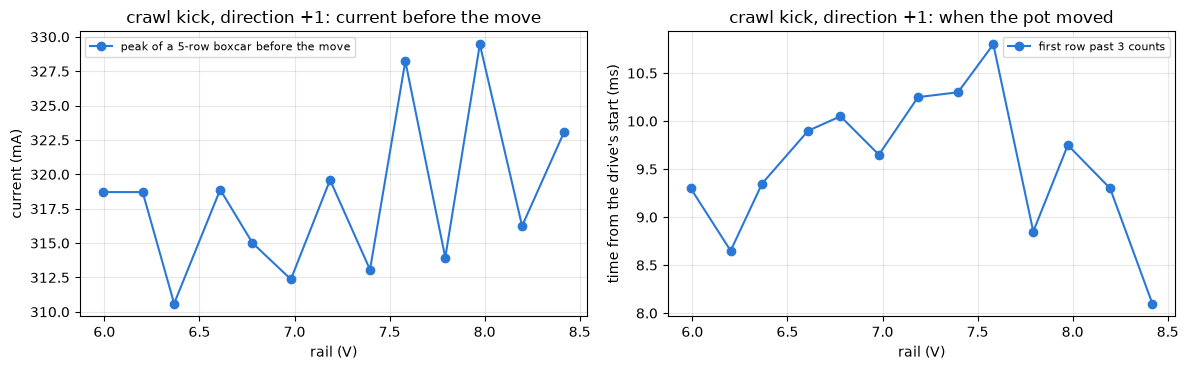

In [59]:
fwd = CRAWL[CRAWL["dir"] == 1]
rev = CRAWL[CRAWL["dir"] == -1]
print(f"+1: moved {fwd['break_ms'].mean():.1f} ms sd "
      f"{fwd['break_ms'].std():.1f} after the drive started, peak "
      f"{fwd['i_break_peak_a'].mean() * 1e3:.0f} mA sd "
      f"{fwd['i_break_peak_a'].std() * 1e3:.0f} before the move, "
      f"{fwd['i_at_move_a'].mean() * 1e3:.0f} mA at the move row; kick "
      f"end {fwd['kick_end_rev_s'].mean():.0f} rev/s")
print(f"-1: rows before the drive {rev['pre_rows'].tolist()}, counts moved "
      f"in them {rev['entry_counts'].tolist()}; kick end "
      f"{rev['kick_end_rev_s'].mean():.0f} rev/s")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(fwd["rail_v"], fwd["i_break_peak_a"] * 1e3, "o-", color=BLUE,
           label="peak of a 5-row boxcar before the move")
ax[1].plot(fwd["rail_v"], fwd["break_ms"], "o-", color=BLUE,
           label="first row past 3 counts")
for a in ax:
    a.legend(fontsize=8)
figures.label(ax[0], x="rail (V)", y="current (mA)",
              title="crawl kick, direction +1: current before the move")
figures.label(ax[1], x="rail (V)", y="time from the drive's start (ms)",
              title="crawl kick, direction +1: when the pot moved")
figures.finish(fig)

In direction +1 the pot leaves its seat 9.6 +/- 0.7 ms after the drive starts, and the current has already reached the stall level, 318 +/- 6 mA, by then. No torque threshold is resolved. The leading reading is backlash taken up before the output moves. In direction -1 the stream opens with the shaft drifting back from the seek, 0 to 13 counts of motion before the drive, and no breakaway is measurable.

The speed down the hold in 50 ms bins, pot and ripple count, and the variation of the bins after the first 200 ms per rail. The thing to see is how much the pot's speed swings while the ripple count holds.

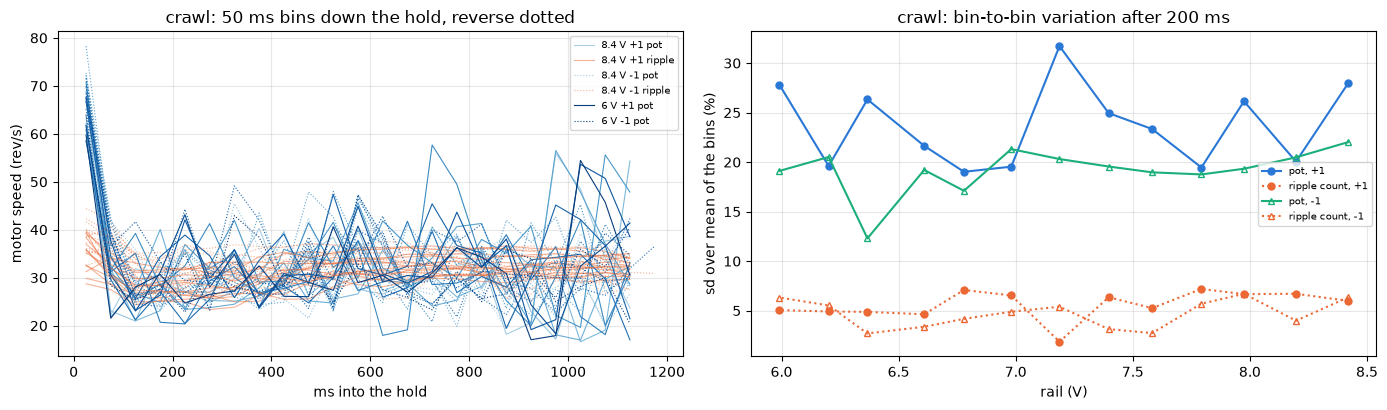

In [60]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
colors = figures.shades("Blues", BINS["volts_set"].nunique())
for (volts, g), color in zip(sorted(BINS.groupby("volts_set"),
                                    reverse=True), colors):
    for d, ls in ((1, "-"), (-1, ":")):
        h = g[g["dir"] == d]
        top = volts in (8.4, 6.0)
        ax[0].plot(h["t_ms"], h["rev_s"].abs(), ls=ls, lw=0.8, color=color,
                   label=f"{volts:g} V {d:+d} pot" if top else None)
        ax[0].plot(h["t_ms"], h["ripple_rev_s"], ls=ls, lw=0.8, alpha=0.5,
                   color=ORANGE,
                   label=f"{volts:g} V {d:+d} ripple" if volts == 8.4
                   else None)
for d, color in ((1, BLUE), (-1, GREEN)):
    g = CRAWL[CRAWL["dir"] == d]
    ax[1].plot(g["rail_v"], g["bins_cv_pct"], ms=5, label=f"pot, {d:+d}",
               **{**figures.direction_style(d, color), "ls": "-"})
    ax[1].plot(g["rail_v"], g["rbins_cv_pct"], ms=5,
               label=f"ripple count, {d:+d}",
               **{**figures.direction_style(d, ORANGE), "ls": ":"})
ax[0].legend(fontsize=7)
ax[1].legend(fontsize=7)
figures.label(ax[0], x="ms into the hold", y="motor speed (rev/s)",
              title="crawl: 50 ms bins down the hold, reverse dotted")
figures.label(ax[1], x="rail (V)", y="sd over mean of the bins (%)",
              title="crawl: bin-to-bin variation after 200 ms")
figures.finish(fig)

In [61]:
print(f"pot bins {CRAWL['bins_min_rev_s'].min():.0f} to "
      f"{CRAWL['bins_max_rev_s'].max():.0f} rev/s, variation "
      f"{CRAWL['bins_cv_pct'].mean():.0f} % ({CRAWL['bins_cv_pct'].min():.0f}"
      f" to {CRAWL['bins_cv_pct'].max():.0f}); ripple bins "
      f"{CRAWL['rbins_min_rev_s'].min():.0f} to "
      f"{CRAWL['rbins_max_rev_s'].max():.0f} rev/s, variation "
      f"{CRAWL['rbins_cv_pct'].mean():.1f} % "
      f"({CRAWL['rbins_cv_pct'].min():.1f} to "
      f"{CRAWL['rbins_cv_pct'].max():.1f})")

pot bins 17 to 78 rev/s, variation 21 % (12 to 32); ripple bins 23 to 44 rev/s, variation 5.2 % (1.9 to 7.2)


In 50 ms bins the pot's speed swings 17 to 78 rev/s, a variation of 21 %, while the ripple count over the same bins stays at 23 to 44 rev/s, 5.2 %. The two read the same mean. A motor in stick-slip would swing both. The bin speeds against the pot's position, every rail on one panel per direction, with the mean over the rails, tell where the pot's swing comes from.

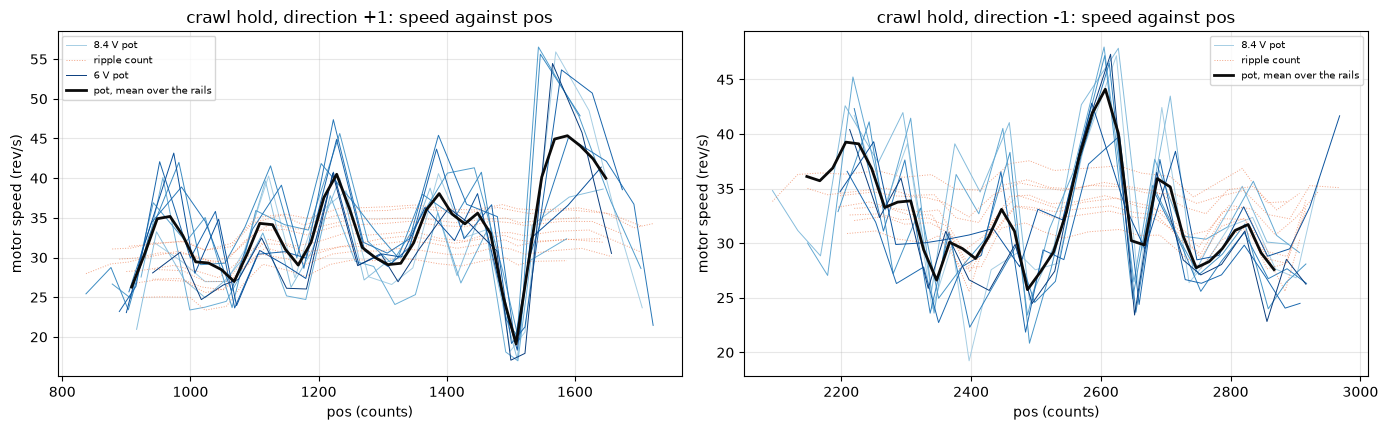

In [62]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
for d, a in ((1, ax[0]), (-1, ax[1])):
    p = PATTERN[d]
    colors = figures.shades("Blues", len(p["kept"]))
    for (volts, h), color in zip(p["kept"], colors):
        a.plot(h["pos_mid"], h["rev_s"], "-", lw=0.7, color=color,
               label=f"{volts:g} V pot" if volts in (8.4, 6.0) else None)
        a.plot(h["pos_mid"], h["ripple_rev_s"], ":", lw=0.7, alpha=0.6,
               color=ORANGE, label="ripple count" if volts == 8.4 else None)
    a.plot(p["grid"], p["mean_curve"], "-", lw=2, color=INK,
           label="pot, mean over the rails")
    a.legend(fontsize=7)
    figures.label(a, x="pos (counts)", y="motor speed (rev/s)",
                  title=f"crawl hold, direction {d:+d}: speed against pos")
figures.finish(fig)

In [63]:
for d in (1, -1):
    p = PATTERN[d]
    deg = p["period_counts"] / SERVO.counts_per_deg_nominal
    print(f"{d:+d}: {p['rails']} rails over pos {p['span'][0]:.0f} to "
          f"{p['span'][1]:.0f}; pot curves r {p['r_mean']:.2f} "
          f"({p['r_min']:.2f} to {p['r_max']:.2f}), ripple curves r "
          f"{p['ripple_r_mean']:.2f}; pattern sd {p['pattern_sd']:.1f} on "
          f"{p['pattern_mean']:.1f} rev/s, rail to rail at a pos "
          f"{p['rail_sd']:.1f}; period {p['period_counts']:.0f} counts, "
          f"{deg:.1f} degrees (nominal)")

+1: 9 rails over pos 908 to 1656; pot curves r 0.76 (0.58 to 0.94), ripple curves r 0.99; pattern sd 5.7 on 33.5 rev/s, rail to rail at a pos 3.6; period 179 counts, 9.0 degrees (nominal)
-1: 8 rails over pos 2147 to 2886; pot curves r 0.71 (0.50 to 0.97), ripple curves r 0.91; pattern sd 4.5 on 32.7 rev/s, rail to rail at a pos 2.9; period 395 counts, 19.9 degrees (nominal)


The pot's pattern repeats against position across the rails, with a pairwise correlation of 0.76 in direction +1 over nine rails and 0.71 in direction -1 over eight. Its strongest period is 179 counts, 9 degrees of output, forward, and 395 counts, 20 degrees, in reverse. The ripple count's curves are flat and correlate 0.99 and 0.91, on their small variation. Likely, the pot's apparent crawl ripple is fixed to output position, either the pot's local gain or the final gear's transmission error, and it is not the motor's. The camera pot-table sweep over the same range separates the two. The motor's own stick-slip at the crawl is about 5 % over 50 ms.

## The cycle against the rail

The 30 % spin's speed, current and $K_e$ by direction.

In [64]:
settle = (CYCLE["ripple_rev_s"] / CYCLE["ripple_prev_rev_s"] - 1) * 100
print(f"spins {CYCLE['spin_ms'].min():.0f} to {CYCLE['spin_ms'].max():.0f}"
      f" ms; last 100 ms over the previous 100 ms {settle.mean():+.1f} % sd"
      f" {settle.std():.1f}, at most {settle.abs().max():.1f} %")
CYCLE_FIT = {}
for d, g in CYCLE.groupby("dir"):
    f = fit_line(g["rail_v"], g["ripple_rev_s"])
    fi = fit_line(g["rail_v"], g["i_a"] * 1e3)
    fk = fit_line(g["rail_v"], g["ke_mv_per_rev_s"])
    CYCLE_FIT[d] = f
    print(f"  {d:+d}: speed on the rail {f['slope']:.1f} +/- "
          f"{f['slope_se']:.1f} rev/s per V, intercept "
          f"{f['intercept']:+.0f}, rms {f['rms']:.1f}; current "
          f"{g['i_a'].min() * 1e3:.0f} to {g['i_a'].max() * 1e3:.0f} mA, "
          f"{fi['slope']:+.1f} +/- {fi['slope_se']:.1f} mA/V; Ke "
          f"{g['ke_mv_per_rev_s'].mean():.3f} sd "
          f"{g['ke_mv_per_rev_s'].std():.3f}, on the rail "
          f"{fk['slope']:+.3f} +/- {fk['slope_se']:.3f}")
split = CYCLE.pivot(index="volts_set", columns="dir", values="ripple_rev_s")
SPLIT = (split[1] / split[-1] - 1) * 100
RP = (CYCLE["ripple_rev_s"] / CYCLE["pot_abs_rev_s"] - 1) * 100
RC = (CYCLE["coast_rev_s"] / CYCLE["ripple_rev_s"] - 1) * 100
print(f"+1 over -1: {SPLIT.mean():+.1f} % sd {SPLIT.std():.1f}; ripple "
      f"over pot {RP.mean():+.1f} % sd {RP.std():.1f}; coast window over "
      f"the spin {RC.mean():+.1f} % sd {RC.std():.1f}")
print(f"coasts stop {CYCLE['stop_ms'].min():.0f} to "
      f"{CYCLE['stop_ms'].max():.0f} ms past the cut, open rows "
      f"{int(CYCLE['open_rows'].sum())}")

spins 202 to 335 ms; last 100 ms over the previous 100 ms +4.9 % sd 3.4, at most 10.4 %
  -1: speed on the rail 33.7 +/- 0.2 rev/s per V, intercept -26, rms 0.5; current 111 to 137 mA, +10.4 +/- 0.4 mA/V; Ke 7.322 sd 0.024, on the rail -0.021 +/- 0.007
  +1: speed on the rail 31.5 +/- 0.2 rev/s per V, intercept -15, rms 0.6; current 112 to 146 mA, +13.4 +/- 0.6 mA/V; Ke 7.332 sd 0.016, on the rail -0.010 +/- 0.005
+1 over -1: -2.1 % sd 0.6; ripple over pot +1.2 % sd 2.8; coast window over the spin -9.4 % sd 1.5
coasts stop 88 to 123 ms past the cut, open rows 0


The spin's ripple speed over its last 100 ms and the coast window's speed, against the rail. The thing to see is the line the spin follows and how far under it the coast window sits.

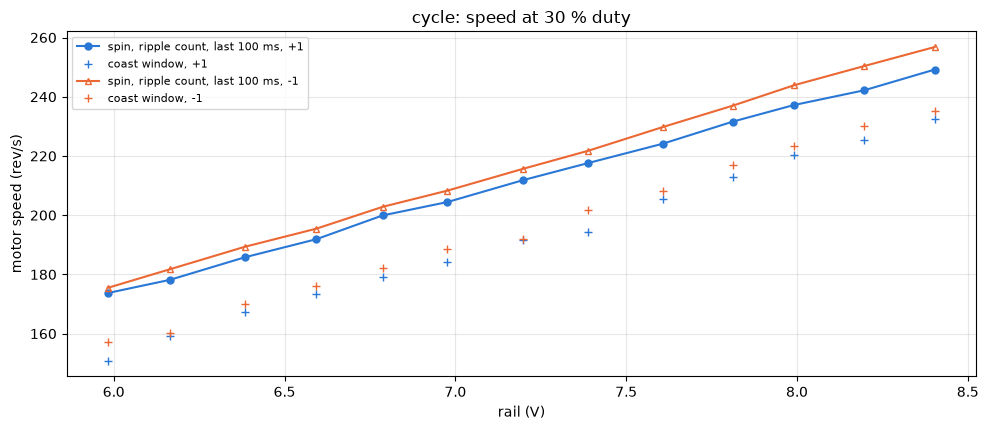

In [65]:
fig, ax = plt.subplots(figsize=(10, 4.4))
for d, color in ((1, BLUE), (-1, ORANGE)):
    g = CYCLE[CYCLE["dir"] == d]
    style = {**figures.direction_style(d, color), "ls": "-"}
    ax.plot(g["rail_v"], g["ripple_rev_s"], ms=5,
            label=f"spin, ripple count, last 100 ms, {d:+d}", **style)
    ax.plot(g["rail_v"], g["coast_rev_s"], ls="none", ms=6, marker="+",
            color=color, label=f"coast window, {d:+d}")
ax.legend(fontsize=8)
figures.label(ax, x="rail (V)", y="motor speed (rev/s)",
              title="cycle: speed at 30 % duty")
figures.finish(fig)

The 30 % spin is not settled. Its last 100 ms reads +4.9 % over the 100 ms before, sd 3.4, and up to +10 % at 8.4 V, where the runway cut the spin to 202 ms. The speed at the end of the spin follows the rail at 31.5 +/- 0.2 rev/s per volt in direction +1 and 33.7 +/- 0.2 in direction -1, with intercepts of -15 and -26 rev/s and residuals of 0.5 to 0.6 rev/s rms, a straight band over 6.0 to 8.4 V. Direction +1 runs 2.1 % slower, sd 0.6. The ripple count reads +1.2 % over the pot, sd 2.8. The coast's window sits 9.4 % under the spin's last 100 ms, sd 1.5. The geared rotor decelerates to a stop in 88 to 123 ms, so the window 1 to 11 ms past the cut is already down the ramp, and a speed at the cut needs the extrapolation to $E_0$ that bemf-coast describes.

The spin's current against the rail. The thing to see is the current rising with the rail and the direction that draws more.

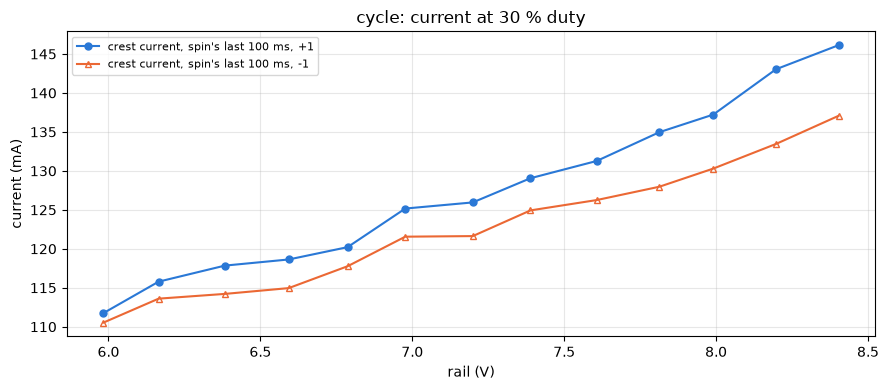

In [66]:
fig, ax = plt.subplots(figsize=(9, 4))
for d, color in ((1, BLUE), (-1, ORANGE)):
    g = CYCLE[CYCLE["dir"] == d]
    style = {**figures.direction_style(d, color), "ls": "-"}
    ax.plot(g["rail_v"], g["i_a"] * 1e3, ms=5,
            label=f"crest current, spin's last 100 ms, {d:+d}", **style)
ax.legend(fontsize=8)
figures.label(ax, x="rail (V)", y="current (mA)",
              title="cycle: current at 30 % duty")
figures.finish(fig)

The spin's current is 111 to 146 mA and rises 10 to 13 mA per volt of rail as the speed does. Direction +1 draws about 5 mA more while turning 2 % slower. A brush drop that differs by direction and a gear drag that differs by direction both fit, and the run-up coasts' $K_e$ by direction with the load experiment separate them.

$K_e$ from each coast against the rail, with the type and the second motor. The thing to see is where mg90-d's motor sits against the type's bracket.

Ke of mg90-d from 26 coasts: 7.327 mV per rev/s (1.1661 mV s/rad), sd 0.021, se 0.004
type mg90-b 7.341 [7.292, 7.367], mg90-c 7.316; -0.20 % on the type


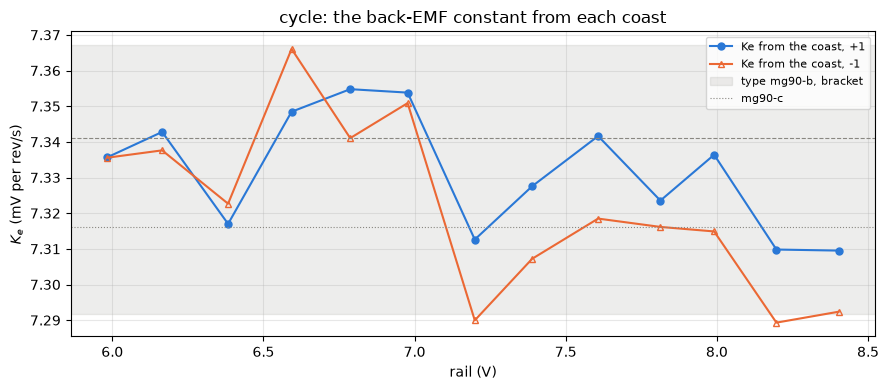

In [67]:
ke = CYCLE["ke_mv_per_rev_s"]
ke_t = BC_TYPE["ke_mv_per_rev_s"]
print(f"Ke of {MOTOR.key} from {len(ke)} coasts: {ke.mean():.3f} mV per "
      f"rev/s ({CYCLE['ke_v_s_per_rad'].mean() * 1e3:.4f} mV s/rad), sd "
      f"{ke.std():.3f}, se {ke.std() / np.sqrt(len(ke)):.3f}")
print(f"type {TYPE_KEY} {ke_t['value']:.3f} [{ke_t['lo']:.3f}, "
      f"{ke_t['hi']:.3f}], mg90-c "
      f"{BC_SPREAD['ke_mv_per_rev_s']['value']:.3f}; "
      f"{(ke.mean() / KE_TYPE_MV - 1) * 100:+.2f} % on the type")
fig, ax = plt.subplots(figsize=(9, 4))
for d, color in ((1, BLUE), (-1, ORANGE)):
    g = CYCLE[CYCLE["dir"] == d]
    style = {**figures.direction_style(d, color), "ls": "-"}
    ax.plot(g["rail_v"], g["ke_mv_per_rev_s"], ms=5,
            label=f"Ke from the coast, {d:+d}", **style)
ax.axhspan(ke_t["lo"], ke_t["hi"], color=MUTED, alpha=0.15,
           label=f"type {TYPE_KEY}, bracket")
ax.axhline(KE_TYPE_MV, color=MUTED, ls="--", lw=0.8)
ax.axhline(BC_SPREAD["ke_mv_per_rev_s"]["value"], color=MUTED, ls=":",
           lw=0.8, label="mg90-c")
ax.legend(fontsize=8)
figures.label(ax, x="rail (V)", y=r"$K_e$ (mV per rev/s)",
              title="cycle: the back-EMF constant from each coast")
figures.finish(fig)

mg90-d's motor reads $K_e$ = 7.327 mV per rev/s, 1.166 mV s/rad, sd 0.021 (0.28 %), from 26 coasts. The type reads 7.341, 7.292 to 7.367, and mg90-c 7.316, so mg90-d sits 0.20 % under the type and inside its bracket, which makes it likely the same motor within the family's spread. The fall with the rail, -0.010 and -0.021 mV per rev/s per volt by direction, is 2 to 3 sigma and is not a finding on its own.

The BEMF speed at 30 %, with the type $R$ and $K_e$, against the spin's ripple speed.

In [68]:
bp = (CYCLE["bemf_pred_rev_s"] / CYCLE["ripple_rev_s"] - 1) * 100
bpc = (CYCLE["bemf_pred_corr_rev_s"] / CYCLE["ripple_rev_s"] - 1) * 100
print(f"BEMF speed on the crest current over the ripple: {bp.mean():+.1f} "
      f"% sd {bp.std():.1f}; with the type term out {bpc.mean():+.1f} % "
      f"sd {bpc.std():.1f}")

BEMF speed on the crest current over the ripple: -0.5 % sd 0.5; with the type term out +8.1 % sd 0.6


On the crest current the BEMF speed closes to -0.5 % at 30 %, sd 0.5. With the type's reading term out it opens to +8.1 %, sd 0.6. So at 30 % the uncorrected estimate closes and the correction alone opens an 8 % gap. Taking the term out and keeping the estimate closed would need the speed-dependent part of the brush drop to carry 130 to 140 mV at 170 to 260 rev/s, which is the ladder notebook's question. The rule this follows is that the reading term and that brush term go in together or not at all.

## The hold through the steps

held-5's two windows, scored over their last 50 ms.

In [69]:
before, after = WINDOWS.iloc[0], WINDOWS.iloc[1]
change = (after["r_app_settled_ohm"] / before["r_app_settled_ohm"] - 1)
ratio_i = before["i_settled_a"] / after["i_settled_a"]
v0_two = ((before["v_eff_settled_v"] - after["v_eff_settled_v"] * ratio_i)
          / (1 - ratio_i))              # V0 through the two points
print(f"settled: I {before['i_settled_a'] * 1e3:.1f} -> "
      f"{after['i_settled_a'] * 1e3:.1f} mA (sd "
      f"{before['i_settled_sd_ma']:.1f}, {after['i_settled_sd_ma']:.1f}), "
      f"V_eff {before['v_eff_settled_v']:.3f} -> "
      f"{after['v_eff_settled_v']:.3f} V")
print(f"V_eff / I {before['r_app_settled_ohm']:.3f} -> "
      f"{after['r_app_settled_ohm']:.3f} ohm ({change * 100:+.1f} %), "
      f"two-point V0 {v0_two:+.3f} V")
print(f"whole windows: I {before['i_a'] * 1e3:.1f} and "
      f"{after['i_a'] * 1e3:.1f} mA, V_eff / I {before['r_app_ohm']:.3f} "
      f"and {after['r_app_ohm']:.3f} ohm")
print(f"before window's first 25 ms: {before['i_first25ms_min_a'] * 1e3:.0f}"
      f" to {before['i_first25ms_max_a'] * 1e3:.0f} mA, pos "
      f"{before['pos_max']:.0f} -> {before['pos_mean']:.0f}")
joules = 0.5 * (before["v_eff_settled_v"] * before["i_settled_a"]
                + after["v_eff_settled_v"] * after["i_settled_a"]) * 36.2
print(f"about {joules:.1f} J into the winding over the 36.2 s hold")

settled: I 229.9 -> 176.8 mA (sd 1.0, 0.9), V_eff 0.982 -> 0.773 V
V_eff / I 4.273 -> 4.370 ohm (+2.3 %), two-point V0 +0.074 V
whole windows: I 224.8 and 176.7 mA, V_eff / I 4.371 and 4.374 ohm
before window's first 25 ms: 178 to 239 mA, pos 2026 -> 2023
about 6.6 J into the winding over the 36.2 s hold


In [70]:
first5, mean_after = after["i_first5_a"], after["i_a"]
HELD_RESET = bool(abs(first5 - mean_after) >= 0.01)   # rise from zero
print(f"after window: first row {after['i_first_row_a'] * 1e3:.0f} mA, "
      f"first 5 rows {first5 * 1e3:.0f}, last 5 "
      f"{after['i_last5_a'] * 1e3:.0f}, mean {mean_after * 1e3:.0f}; "
      f"reset signature {HELD_RESET}")
print(f"asleep zero {HELD_ZERO_I:.1f}; the 5 rows before the drive "
      f"{before['pre_current_mean']:.1f} counts, "
      f"{before['pre_current_mean'] - HELD_ZERO_I:+.1f} over it")
print(f"seat {SEATS['pos'].iloc[0]} -> {SEATS['pos'].iloc[1]}, shift "
      f"{SEATS['shift_counts'].iloc[1]} counts; in the windows "
      f"{before['pos_min']:.0f} to {before['pos_max']:.0f}, then "
      f"{after['pos_min']:.0f} to {after['pos_max']:.0f}")

after window: first row 177 mA, first 5 rows 177, last 5 178, mean 177; reset signature False
asleep zero 1208.0; the 5 rows before the drive 1216.6 counts, +8.6 over it
seat 2027 -> 2022, shift 5 counts; in the windows 2021 to 2026, then 2019 to 2025


The two windows, the current over the zero, the crest tap difference and the pot. The thing to see is whether the after window opens on the held current or climbs from zero, which is what a reset would leave.

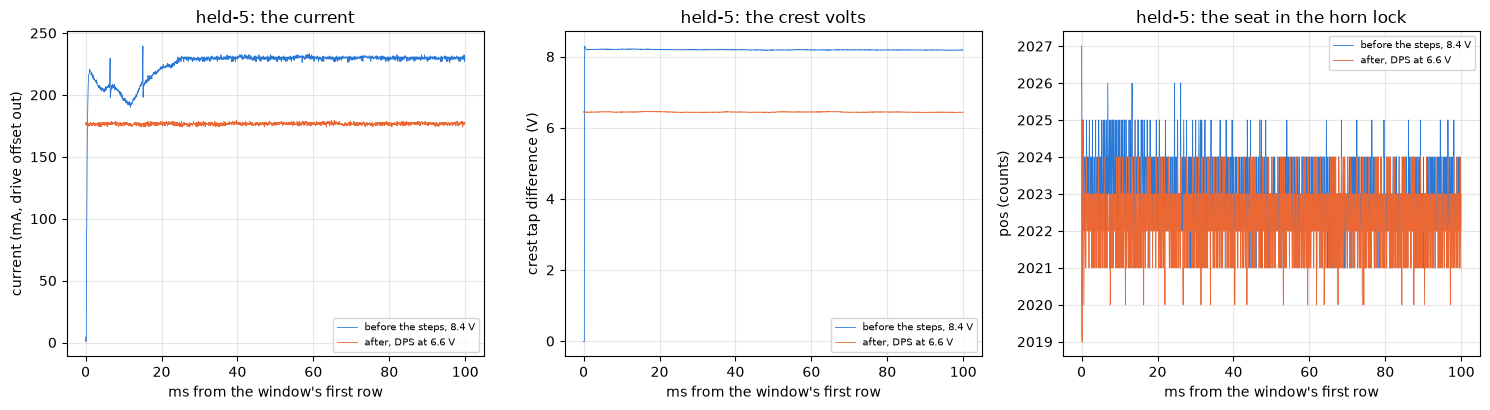

In [71]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for seg, color, name in ((1, BLUE, "before the steps, 8.4 V"),
                         (3, ORANGE, f"after, DPS at {level_after} V")):
    g = HELD_DF[HELD_DF["seg"] == seg]
    ms = np.arange(len(g)) / FS * 1e3
    d = int(g["dir"].iloc[0])
    ax[0].plot(ms, amps(g["current_raw"], HELD_ZERO_I) * 1e3, lw=0.6,
               color=color, label=name)
    ax[1].plot(ms, volts_on(g, d), lw=0.6, color=color, label=name)
    ax[2].plot(ms, g["pos"], lw=0.6, color=color, label=name)
figures.label(ax[0], x="ms from the window's first row",
              y="current (mA, drive offset out)",
              title="held-5: the current")
figures.label(ax[1], x="ms from the window's first row",
              y="crest tap difference (V)", title="held-5: the crest volts")
figures.label(ax[2], x="ms from the window's first row", y="pos (counts)",
              title="held-5: the seat in the horn lock")
for a in ax:
    a.legend(fontsize=7)
figures.finish(fig)

The data holds no reset signature, likely. The after window opens with the current already at its held 177 mA from its first row, where a reset would restart from zero over about 4 rows and fault the hold. The duty is -3932 in q15 on every row, the sweep dropped no rows, the windows have no tick gaps, the sitting ran on to its end with no error logged, the plant stamp matches 0x9c45, and the seat moved 2027 to 2022, 5 counts, inside the 10 count rule. The before window's first 25 ms holds the horn seating into the lock, 178 to 239 mA with the pot moving 2026 to 2023, which the 50 ms score leaves out.

The hold did not see the rails the plan meant it to. Each DPS step took 3.8 s where the plan asked for 2.0, so the hold, 36.1 s unstreamed, ended during the 6.6 V step. The after window saw 6.6 V, 1.27 s into that step, not 6.0 V, and 6.4, 6.2 and 6.0 V were stepped with the drive over. Nine steps ran under a 177 to 230 mA stall and three with torque off. The 6.0 V end state exists only as the manifest's probe after the hold, `vbus_raw` 1488 against capture-1's 1489 at 6.0 V.

Settled, the current falls 229.9 to 176.8 mA and $V_\mathrm{eff}$ 0.982 to 0.773 V, and $V_\mathrm{eff} / I$ rises 4.273 to 4.370 ohm, +2.3 %. The 36 s of warming and the before window's crest over-read are inseparable here, so the change is a candidate. The two-point $V_0$, +0.074 V, is a candidate on the same footing. The data holds no settling time constant, since the hold was not streamed and the DPS readback is the setpoint echo once per step.

## What the duty cap and the zero tracker take from this

The 5 V cap and the duty that holds 1.0 V effective at each rail, and their steps per 0.2 V. The thing to see is how much finer the firmware has to track the rail near the floor than near a full pack.

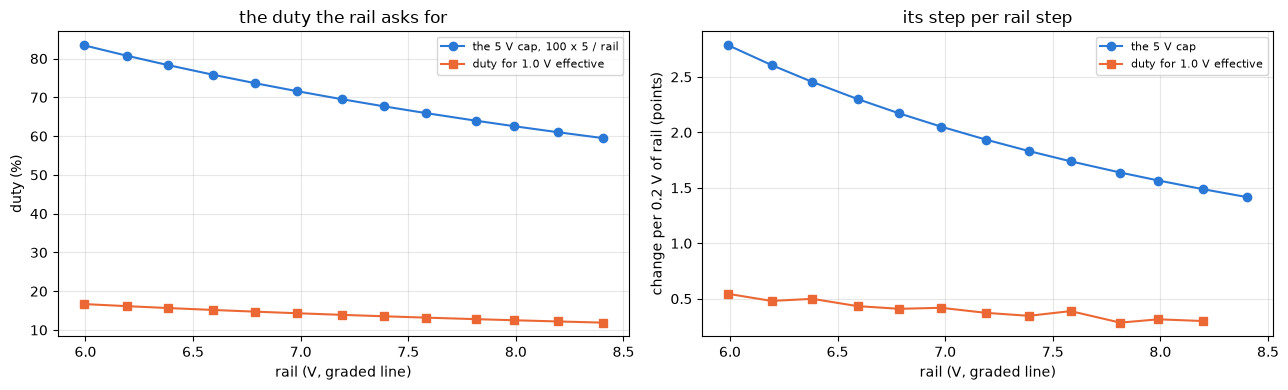

duty for 1.0 V: 11.90 % (143 ticks) at 8.4 V to 16.69 % (200 ticks) at 6.0 V, 0.28 to 0.54 points per step


In [72]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(CAP["rail_tc_v"], CAP["cap_5v_pct"], "o-", color=BLUE,
           label="the 5 V cap, 100 x 5 / rail")
ax[0].plot(CAP["rail_tc_v"], CAP["duty_for_1v_pct"], "s-", color=ORANGE,
           label="duty for 1.0 V effective")
ax[1].plot(RAIL["rail_tc_v"], RAIL["cap_step_pts_per_0v2"], "o-",
           color=BLUE, label="the 5 V cap")
ax[1].plot(CAP["rail_tc_v"], CAP["step_pts"].abs(), "s-", color=ORANGE,
           label="duty for 1.0 V effective")
for a in ax:
    a.legend(fontsize=8)
figures.label(ax[0], x="rail (V, graded line)", y="duty (%)",
              title="the duty the rail asks for")
figures.label(ax[1], x="rail (V, graded line)",
              y="change per 0.2 V of rail (points)",
              title="its step per rail step")
figures.finish(fig)
steps = CAP["step_pts"].abs().iloc[1:]
print(f"duty for 1.0 V: {CAP['duty_for_1v_pct'].iloc[0]:.2f} % "
      f"({CAP['ticks_for_1v'].iloc[0]:.0f} ticks) at 8.4 V to "
      f"{CAP['duty_for_1v_pct'].iloc[-1]:.2f} % "
      f"({CAP['ticks_for_1v'].iloc[-1]:.0f} ticks) at 6.0 V, "
      f"{steps.min():.2f} to {steps.max():.2f} points per step")

For the duty cap, the board reads a still rail within 20 mV at every state of charge, so the graded rest line is good to 0.3 % for the cap's arithmetic. The cap runs 59.5 to 83.5 % and moves 1.42 to 2.79 points per 0.2 V, and holding 1.0 V effective takes 11.90 % at 8.4 V to 16.69 % at 6.0 V, 0.28 to 0.54 points per step. The cap and any held effective drive change twice as fast per volt near the floor as on a full pack. The cap's "rail at rest" is not the rail under a stall on a real pack, see the Limitations.

For the zero tracker, the asleep zero is flat to under a count over 2S and the awake step is a flat +8.1 mA, so over 6.0 to 8.4 V the data asks for no rail term, only the asleep-to-awake step.

For the undervolt design, a held effective drive gives the same crawl at every rail, 26 of 26 turning, and the 30 % spin's speed is a line on the rail. One held stall rode nine steps down to 6.6 V without a reset.

### The result file

The notes that define every key.

In [73]:
NOTES = (
    "stage 3 sag of mg90-d on dev-v006-2A-D, capture-1 (thirteen rails "
    "8.4 to 6.0 V, 0.2 V apart, from the DPS-150 over the feed diode, each "
    "trimmed at rest; at each a 300 ms stop lap of 1.5 V effective into "
    "the low stop, a crawl both ways, a 150 ms kick at 1.5 V effective "
    "then a hold at 0.5 V effective then a 400 ms coast, and a 30 % spin "
    "and coast both ways) and held-5 (a 12 % stall into the horn lock "
    "while the DPS stepped down, two 100 ms windows, the hold unstreamed). "
    "Current through stage 1 current-scale over each sweep's torque-off "
    "zero with the in-drive offset out, the crest sample; terminal and "
    "rail volts through stage 1 terminal-chain, the rail from the three "
    "torque-off probes per rail in the sitting manifest (TEL rows carry "
    "no vbus_raw). rail_read_minus_set_mv is the mean of the 13 per-rail "
    "differences of the graded line from the level with their range as "
    "bounds; rail_line_slope the line of the graded rail on the level, "
    "its se as bounds, rail_read_rms_mv its rms; rail_probe_spread_counts "
    "the median and range of the three probes' spread per rail; "
    "diode_drop_v the DPS setpoint less the runner's read, mean and range "
    "(dps_read is a setpoint echo); rail_minus_crest_von_mv the rail at "
    "rest less the crest tap difference under the 0.33 A stop lap, mean "
    "and range; cap_5v_pct_* the cap 100 x 5 / rail at 8.4 and 6.0 V; "
    "cap_step_pts_per_0v2 its step per 0.2 V, at 8.4 V with 8.4 V (lo) "
    "and 6.0 V (hi) as bounds. zero_asleep_counts the mean of the 39 "
    "sweeps' baseline means, the range of the baseline medians as bounds; "
    "zero_asleep_per_v_counts its line on the rail, se bounds, report "
    "only; zero_awake_step_* the last 100 ms of each of the 52 coast "
    "tails, bridge open and rotor at rest, over the same sweep's asleep "
    "zero, mean +/- sd; zero_awake_step_per_v_counts its line on the "
    "rail, se bounds. r_stop_lap_ohm is mean V_eff over mean crest "
    "current from 2 ms into each lap, mean of the 13 laps with their "
    "range as bounds, a candidate with V0 and any constant crest offset "
    "folded in, one commutator angle (the seat never moved, the pot blind "
    "on the ADC rail at the low stop); r_stop_lap_sd_pct its sd; "
    "r_stop_lap_per_v_ohm its line on the rail, se bounds; "
    "crest_over_read_per_von_locked_ma_per_v the reading term that slope "
    "implies through -R^2 G / V_eff with R the type-corrected mean, se "
)

In [74]:
NOTES += (
    "bounds; r_stop_lap_type_reading_term_ohm the same ratio with the "
    "stage 2 type reading term (mg90-b, 4.29 mA/V) taken out of the "
    "current, comparison only, mean and range, rail dependent; "
    "lap_warming_pct the last 50 ms over the first 50 ms, mean +/- sd; "
    "lap_current_a mean and range. crawl_*: the hold's last 400 ms, speed "
    "through the nominal pot slope (19.8 counts per degree) and the "
    "counted 308.05:1 train, motor rev/s; crawl_kept_turning_n of "
    "crawl_hold_n holds had no 50 ms bin under 0.5 rev/s, one session; "
    "crawl_speed_rev_s mean and range, crawl_speed_sd_rev_s its sd; "
    "crawl_v_eff_v and crawl_current_ma mean and range; "
    "crawl_current_per_v_ma the mean of the two directions' slopes on the "
    "rail, their se in quadrature over two as bounds; "
    "crawl_current_excess_ma the crest current over (V_eff - Ke w_pot) / "
    "R with the type Ke (0.2 % from this motor's) and r_stop_lap_ohm, "
    "mean +/- sd, the hi end "
    "reaching the type-corrected R's value; crawl_ripple_over_pot_pct the "
    "ripple count over the pot, mean +/- sd; crawl_*_bin_cv_pct the sd "
    "over mean of the 50 ms bins after 200 ms, mean and range; "
    "crawl_pattern_pos_corr the pairwise r of the pot's bin speeds "
    "against position across rails, mean of the two directions with each "
    "direction as a bound; crawl_bemf_speed_*_pct the BEMF speed (V_eff - "
    "R_type I) / Ke_type on the crest current and with the type term out, "
    "over the pot. kick_breakaway_ms_fwd the first row 3 counts past the "
    "seat in direction +1, mean +/- sd (the reverse stream opens with the "
    "shaft moving, no breakaway); kick_current_at_move_a the peak of a "
    "5-row boxcar of the current from the drive's start to that row, mean "
    "+/- sd. cycle_*: the 30 % spin's last 100 ms; "
    "cycle_speed_per_v_rev_s_fwd and _rev the ripple speed's line on the "
    "rail per direction, se bounds, from spins that had not settled; "
    "cycle_speed_settle_pct the last 100 ms over the 100 ms before, "
    "cycle_direction_split_pct +1 over -1, cycle_ripple_over_pot_pct and "
    "coast_window_under_spin_pct mean +/- sd; ke_* bemf-coast's coast "
    "route on the 26 coasts, mean +/- sd, ke_over_type_pct against mg90-b; "
)

In [75]:
NOTES += (
    "cycle_bemf_speed_*_pct the BEMF speed with the type R and Ke over "
    "the ripple speed, on the crest current and with the type term out, "
    "mean +/- sd. held_*: held_reset false, the after window's first 5 "
    "rows within 10 mA of its mean, the sweep's rows all present and the "
    "plant stamp matched; held_i_*_a and held_v_eff_*_v the last 50 ms of "
    "the window before the first step (8.4 V) and after the hold; the "
    "DPS steps took 3.8 s against the plan's 2.0, so the after window saw "
    "6.6 V (held_after_window_rail_v) and the last three steps ran with "
    "the drive over; held_r_app_change_pct the change of V_eff / I "
    "between the two, a candidate (warming and the crest over-read are "
    "inseparable); held_seat_shift_counts the horn lock's seat change "
    "over the hold; duty_for_1v_pct_* the duty that holds 1.0 V effective "
    "at 8.4 and 6.0 V from capture-1's rails, "
    "duty_step_for_1v_pts_per_0v2 its step per 0.2 V, smallest with the "
    "range as bounds. The DPS-150 is a stiff source trimmed at rest, so "
    "the rail axis is the state of charge and holds nothing of a pack's "
    "source impedance."
)

The quantities, the rail and the zero first.

In [76]:
def mean_range(x, unit):
    """The mean of `x` with its range as the bounds."""
    x = pd.Series(x).dropna()
    return results.median_range(x, unit, value=x.mean())


q = results.quantity
top, bottom = RAIL.iloc[0], RAIL.iloc[-1]   # 8.4 V and 6.0 V
QUANTITIES = {
    "rail_read_minus_set_mv": mean_range(RAIL["tc_minus_set_mv"], "mV"),
    "rail_read_rms_mv": q(FIT_SET["rms"] * 1e3, unit="mV"),
    "rail_line_slope": results.pm(FIT_SET["slope"], FIT_SET["slope_se"],
                                  "ratio"),
    "rail_probe_spread_counts": results.median_range(
        RAIL["vbus_raw_range"], "counts"),
    "diode_drop_v": mean_range(RAIL["diode_v"], "V"),
    "rail_minus_crest_von_mv": mean_range(RAIL["rail_minus_von_mv"], "mV"),
    "cap_5v_pct_8v4": q(top["cap_pct_tc"], unit="%"),
    "cap_5v_pct_6v0": q(bottom["cap_pct_tc"], unit="%"),
    "cap_step_pts_per_0v2": q(top["cap_step_pts_per_0v2"],
                              top["cap_step_pts_per_0v2"],
                              bottom["cap_step_pts_per_0v2"], "points"),
    "zero_asleep_counts": q(ASLEEP["zero_asleep_mean"].mean(),
                            ASLEEP["zero_asleep"].min(),
                            ASLEEP["zero_asleep"].max(), "counts"),
    "zero_asleep_per_v_counts": results.pm(fa["slope"], fa["slope_se"],
                                           "counts/V"),
    "zero_awake_step_counts": results.mean_sd(AWAKE["step_counts"],
                                              "counts"),
    "zero_awake_step_ma": results.mean_sd(AWAKE["step_ma"], "mA"),
    "zero_awake_step_per_v_counts": results.pm(fw["slope"],
                                               fw["slope_se"], "counts/V"),
}

The stop laps and the crawl.

In [77]:
r_app = STOP["r_app_ohm"]
QUANTITIES.update({
    "r_stop_lap_ohm": mean_range(r_app, "ohm"),
    "r_stop_lap_sd_pct": q(100 * r_app.std() / r_app.mean(), unit="%"),
    "r_stop_lap_per_v_ohm": results.pm(FIT_R["r_app_ohm"]["slope"],
                                       FIT_R["r_app_ohm"]["slope_se"],
                                       "ohm/V"),
    "crest_over_read_per_von_locked_ma_per_v": results.pm(
        G_LOCKED, G_LOCKED_SE, "mA/V", scale=1e3),
    "r_stop_lap_type_reading_term_ohm": mean_range(STOP["r_corr_ohm"],
                                                   "ohm"),
    "lap_warming_pct": results.mean_sd(STOP["warm_pct"], "%"),
    "lap_current_a": mean_range(STOP["i_a"], "A"),
    "crawl_kept_turning_n": q(CRAWL["kept_turning"].sum(), unit="holds"),
    "crawl_hold_n": q(len(CRAWL), unit="holds"),
    "crawl_speed_rev_s": mean_range(CRAWL["pot_abs_rev_s"], "rev/s"),
    "crawl_speed_sd_rev_s": q(CRAWL["pot_abs_rev_s"].std(), unit="rev/s"),
    "crawl_v_eff_v": mean_range(CRAWL["v_eff_v"], "V"),
    "crawl_current_ma": mean_range(CRAWL["i_hold_a"] * 1e3, "mA"),
    "crawl_current_per_v_ma": results.pm(I_PER_V, I_PER_V_SE, "mA/V"),
    "crawl_current_excess_ma": results.mean_sd(CLOSURE["R_lap"], "mA"),
    "crawl_ripple_over_pot_pct": results.mean_sd(rel, "%"),
    "crawl_pot_bin_cv_pct": mean_range(CRAWL["bins_cv_pct"], "%"),
    "crawl_ripple_bin_cv_pct": mean_range(CRAWL["rbins_cv_pct"], "%"),
    "crawl_pattern_pos_corr": q(
        np.mean([PATTERN[d]["r_mean"] for d in (1, -1)]),
        min(PATTERN[d]["r_mean"] for d in (1, -1)),
        max(PATTERN[d]["r_mean"] for d in (1, -1)), "r"),
    "crawl_bemf_speed_crest_pct": q((emf / KE / pot - 1) * 100, unit="%"),
    "crawl_bemf_speed_corrected_pct": q((emf_c / KE / pot - 1) * 100,
                                        unit="%"),
    "kick_breakaway_ms_fwd": results.mean_sd(fwd["break_ms"], "ms"),
    "kick_current_at_move_a": results.mean_sd(fwd["i_break_peak_a"], "A"),
})

The cycle and the hold.

In [78]:
QUANTITIES.update({
    "cycle_speed_per_v_rev_s_fwd": results.pm(
        CYCLE_FIT[1]["slope"], CYCLE_FIT[1]["slope_se"], "rev/s per V"),
    "cycle_speed_per_v_rev_s_rev": results.pm(
        CYCLE_FIT[-1]["slope"], CYCLE_FIT[-1]["slope_se"], "rev/s per V"),
    "cycle_speed_settle_pct": results.mean_sd(settle, "%"),
    "cycle_direction_split_pct": results.mean_sd(SPLIT, "%"),
    "cycle_ripple_over_pot_pct": results.mean_sd(RP, "%"),
    "coast_window_under_spin_pct": results.mean_sd(RC, "%"),
    "ke_v_s_per_rad": results.mean_sd(CYCLE["ke_v_s_per_rad"], "V s/rad"),
    "ke_mv_per_rev_s": results.mean_sd(ke, "mV per rev/s"),
    "ke_over_type_pct": q((ke.mean() / KE_TYPE_MV - 1) * 100, unit="%"),
    "cycle_bemf_speed_crest_pct": results.mean_sd(bp, "%"),
    "cycle_bemf_speed_corrected_pct": results.mean_sd(bpc, "%"),
    "held_reset": HELD_RESET,
    "held_i_before_a": q(before["i_settled_a"], unit="A"),
    "held_i_after_a": q(after["i_settled_a"], unit="A"),
    "held_v_eff_before_v": q(before["v_eff_settled_v"], unit="V"),
    "held_v_eff_after_v": q(after["v_eff_settled_v"], unit="V"),
    "held_r_app_change_pct": q(change * 100, unit="%"),
    "held_seat_shift_counts": q(SEATS["shift_counts"].iloc[1],
                                unit="counts"),
    "held_after_window_rail_v": q(level_after, unit="V"),
    "duty_for_1v_pct_8v4": q(CAP["duty_for_1v_pct"].iloc[0], unit="%"),
    "duty_for_1v_pct_6v0": q(CAP["duty_for_1v_pct"].iloc[-1], unit="%"),
    "duty_step_for_1v_pts_per_0v2": q(steps.min(), steps.min(),
                                      steps.max(), "points"),
})

The result file, then every key as written.

In [79]:
path = results.write("3-servo", "sag", CAPTURE, pair=PAIR, notes=NOTES,
                     **QUANTITIES)
written = results.read("3-servo", "sag", pair=PAIR)
print("wrote", path, "with", len(QUANTITIES), "keys, capture",
      written["capture"])
table = pd.DataFrame([{"key": k, **v} for k, v in written.items()
                      if isinstance(v, dict)])
show(table, n=None)
print("held_reset:", written["held_reset"])

wrote stages/3-servo/sag/results/mg90-d__dev-v006-2A-D.json with 59 keys, capture telemetry/mg90-d__dev-v006-2A-D/sag/capture-1


,key,value,lo,hi,unit
0,rail_read_minus_set_mv,-8.026,-19.028,13.171,mV
1,rail_read_rms_mv,7.531,NaN,NaN,mV
2,rail_line_slope,1.005,1.002,1.008,ratio
3,rail_probe_spread_counts,5.000,1.000,9.000,counts
4,diode_drop_v,0.265,0.248,0.279,V
5,rail_minus_crest_von_mv,281.605,261.183,303.646,mV
6,cap_5v_pct_8v4,59.503,NaN,NaN,%
7,cap_5v_pct_6v0,83.455,NaN,NaN,%
8,cap_step_pts_per_0v2,1.416,1.416,2.786,points
9,zero_asleep_counts,1207.221,1206.000,1208.000,counts


held_reset: False


## Limitations

- The supply is the DPS-150, a stiff source, trimmed at rest before each rail's sweeps. The data holds the state-of-charge axis and nothing of a pack's source impedance. Earlier work in the firmware repo's older notebooks found, on another board and motor, that 01-bridge-states and 02-electrical saw the 2S rail flat with duty at running currents, 7.651 V at 10 % to 7.627 V at 100 %, 0.3 %. 03-back-emf saw about 12 % droop under the stall and inrush window. 10-sense-chain-boards saw 7.73 V at rest fall to 7.40 V at the 100 % rung, about 0.21 ohm of source. 09-pot-linearization and 12-pot-table saw the pack drain 0.1 to 0.5 V over a session. So a stall on a real pack sees a droop of a few hundred millivolts at these currents that the DPS data does not contain. The cap's rail at rest differs from the rail under the stall by the current times about 0.21 ohm plus the pack's state, and the zero tracker and the cap have to be designed for a rail that moves under the drive, which these steps never exercise. On that axis this notebook settles the board's read of a still rail, the duty the cap needs per state of charge, the zero per level, and the crawl and 30 % behavior at a held effective voltage.
- The sweeps' telemetry rows carry no `vbus_raw`. The rail under drive is the crest tap difference, with the bridge's drops in it.
- Each rail has one stop lap at one level, so $R$ and $V_0$ do not separate, and the reading term is probed only through the rail at a fixed current.
- held-5's hold is unstreamed. Its after window saw 6.6 V, not 6.0 V, and the data holds no settling time after a step.
- The low stop's seat is blind in the pot, which reads 0 to 4 counts on the ADC's rail, so the stopper's flex of 60 to 84 counts under the lap is not seen.
- The crawl speeds rest on the pot's nominal slope, 19.8 counts per degree, checked against the ripple tach to +2.4 % at the crawl and +1.2 % at 30 %, and not graded here.
- The 30 % spins had not settled at the top rails, so the cycle's speed lines read speeds still rising.
- One session, one board, one servo, fresh Super Lube in a train that is still running in, and a motor whose brushes are still bedding in.

## Open questions

1. Within-lap warming, +0.05 +/- 0.06 % against the type's +0.34 %. Candidates are the type's per-joule figure taken at 0.78 to 0.85 A with a contact term that bends with current, a crest transient relaxing through the lap, and a smaller copper share at 0.33 A. Laps of 300 ms at 0.33 and 0.75 A on one seat, the resistance experiment's locked laps, read as the rise per joule, separate them.
2. The reading term by regime. Locked at 18 to 25 % it is under 1.3 mA per volt. At the crawl, 6 to 8 % and turning, the crest carries +13 to +18 mA, 1.8 to 2.6 mA per volt with a -32 mA intercept. The type's bare motor at 20 to 40 % gave 4.29 mA per volt, and at 30 % here the uncorrected estimate closes to -0.5 % and the corrected one opens to +8 %. Candidates are a short-window over-read at 72 to 96 ticks, a dependence on speed or load, and the speed-dependent brush term cancelling at 30 %. A crawl ladder of 5 to 10 % at one rail, a locked ladder of 10 to 40 % at one rail, and the ladder notebook's brush-term table separate them.
3. The rail at rest less the crest $V_\mathrm{on}$, 280 mV against 150 to 200 mV from the bridge path. Candidates are the feed diode under load, tap A's low excess, and the torque-off probe. The gap at 0.74 and 0.83 A from the locked laps separates them, a slope saying resistance and a constant saying offset.
4. The crawl's pot speed pattern fixed to position, r 0.71 to 0.76 with periods of 9 to 20 degrees. Candidates are the pot's local gain and the final stage's transmission error. A pot-table sweep against the camera tag over the same range separates them.
5. $K_e$'s 2 to 3 sigma fall with the rail, -0.14 to -0.29 % per volt, about 30 rev/s per volt. Candidates are stage 2's speed trend, three times smaller, and an effect of the window's position on a decelerating geared rotor. $E_0$ extrapolated against the window on the same coasts, and run-up coasts across speed at one rail, separate them.
6. The awake zero step flat at 8.1 mA over 6.0 to 8.4 V, against stage 2's 2 to 8 mA growing over 3.7 to 7.4 V. Candidates are a step that saturates above about 7 V and a difference of board state. The same coast-tail read on this servo's 3.7 and 5.0 V sweeps, ladder/low-1 and ladder/capture-1, separates them.
7. The cycle's direction split of -2.1 % with direction +1 drawing 5 mA more. Candidates are a brush drop that differs by direction and a gear drag that differs by direction. The run-up coasts' $K_e$ by direction and the load notebook separate them.

The data does not settle a pack's droop under a stall, the rail's settling time after a step, $V_0$ and $R$ apart, the cause of the crest offset at a crawl, pot against gear for the crawl's pattern, whether the reset can be reproduced, since one hold saw none, or the steady speed at 30 % on the top rails.

## Conclusion

On a stiff supply stepped from 8.4 V to 6.0 V, the board reads its rail within 20 mV at every level through the stage 1 line, slope 1.0050 +/- 0.0030, so the duty cap, 59.5 to 83.5 %, can be computed from the board's own reading with an error of 0.3 % or less at rest. The cap moves 1.42 points per 0.2 V on a full pack and 2.79 near the floor.

The current zero needs no rail term over 2S. Asleep it reads 1207.2 counts to within a count, and awake, the bridge enabled with its outputs open, it sits +9.20 counts, +8.11 mA, over that, flat with the rail.

The locked stop lap at 1.5 V effective reads $V_\mathrm{eff} / I_\mathrm{crest}$ = 4.344 ohm, sd 0.019, flat with the rail, which says the crest over-read on a locked rotor at 18 to 25 % is small, 0.35 +/- 0.45 mA per volt, against the type's 4.29. The number is a candidate with the brush drop folded in.

At 0.5 V effective the servo kept turning in all 26 holds, at about 31 rev/s at the motor whatever the rail, with the pot's apparent speed ripple fixed to position and the motor's own about 5 %. The crest current at the crawl reads 20 to 30 % over what the motor draws, so a BEMF speed at a crawl is 8 to 10 rev/s off either way. mg90-d's motor reads $K_e$ = 7.327 mV per rev/s, 0.20 % under the type, and the 30 % spin's BEMF speed on the crest current closes to -0.5 %.

A 12 % stall into the horn lock rode nine DPS steps down to 6.6 V with no sign of a reset. The steps ran slower than planned, so 6.4 to 6.0 V were not seen under drive, and a pack's droop under a stall is outside what a stiff supply shows. Those two are what a pack-powered repeat of the held pass has to add.